# Template étudiant — Data Science et commerce international

**Binôme :** Imane Zine El Abdine / Ishrak Driouich 

**Projet :** : 01 — Prévision des exportations marocaines par produit 

**Date :** 13/11/2026

**Important :** notebook volontairement incomplet. Ne pas inventer de données. Garder un journal des sources et paramètres de requêtes.

In [1]:
# Bibliothèques principales
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.pipeline import Pipeline
from sklearn.model_selection import TimeSeriesSplit, train_test_split
GRAINE_ALEATOIRE = 42
print('Versions :', np.__version__, pd.__version__)

Versions : 2.2.4 2.2.3


In [2]:
from pathlib import Path

# Dossiers du projet (chemins relatifs : fonctionnent en local et sur Colab)
DOSSIER_DATA = Path('data')
DOSSIER_FIG = Path('figures')
DOSSIER_DATA.mkdir(exist_ok=True)
DOSSIER_FIG.mkdir(exist_ok=True)

print('Dossier des données :', DOSSIER_DATA.resolve())
print('Dossier des figures :', DOSSIER_FIG.resolve())

Dossier des données : C:\Users\hibaz\Downloads\Projet01_Exports_Maroc\data
Dossier des figures : C:\Users\hibaz\Downloads\Projet01_Exports_Maroc\figures


## 1. Problématique et hypothèses

**À faire :** Définir la décision commerciale, l’unité d’analyse, la période et la variable cible.

**Réponse du binôme :** 

Nous nous plaçons du point de vue d'un exportateur marocain de légumes ou d'un organisme qui accompagne les exportations agricoles. Pour eux, avoir une estimation de la valeur exportée l'année suivante aide à planifier la production, à anticiper les besoins logistiques et à choisir où concentrer la prospection. 

Notre question est la suivante : **à partir des valeurs observées jusqu'à une année t, peut-on prévoir la valeur des exportations marocaines de légumes (chapitre HS 07) pour l'année t+1 ?**

Nous travaillons à l'échelle annuelle : une observation correspond à la valeur totale exportée par le Maroc vers le monde pour le chapitre HS 07 sur une année. La période visée va de 2010 à 2024 ; la couverture réelle sera confirmée après l'extraction. La variable cible est la valeur exportée en t+1, en dollars américains courants (champ `primaryValue` de UN Comtrade).

Nous partons de trois hypothèses :

- **H1** : les exportations d'une année sont proches de celles de l'année précédente, donc une prévision « on reprend la dernière valeur » devrait déjà donner des résultats corrects.
- **H2** : en ajoutant l'information des années passées et la tendance récente, un modèle comme Ridge ou le Gradient Boosting peut faire un peu mieux.
- **H3** : avec seulement une quinzaine d'années, un modèle complexe risque de surapprendre, et son avantage sur la méthode simple sera probablement faible.

## 2. Accès aux données

**À faire :** Coller l’URL officielle et l’URL du fichier/API documentée. Vérifier la licence, quotas, clés et période.

**Réponse du binôme :**

Les données viennent de **UN Comtrade**, la base de la Division de statistique des Nations Unies qui regroupe les échanges de marchandises déclarés par les douanes de chaque pays.

- Documentation : https://uncomtrade.org/docs/un-comtrade-api/
- Point d'accès utilisé (API publique « preview », sans clé) : https://comtradeapi.un.org/public/v1/preview/C/A/HS

Paramètres de la requête :

- `C/A/HS` : marchandises, données annuelles, nomenclature HS
- `reporterCode=504` : Maroc
- `partnerCode=0` : monde
- `flowCode=X` : exportations
- `cmdCode=07` : chapitre HS 07 (légumes)
- `period` : de 2010 à 2024

La version preview n'accepte qu'une seule période par requête et renvoie au maximum 500 lignes. Nous envoyons donc une requête par année, avec une courte pause entre deux appels. Comme nous n'avons besoin que d'une ligne par année, le plafond de 500 lignes ne nous gêne pas. L'accès complet demande un compte et une clé d'abonnement, ce qui n'est pas nécessaire pour notre projet.

Conditions d'utilisation : en utilisant UN Comtrade, même sans abonnement, on accepte ses conditions d'utilisation (https://comtrade.un.org/licenseagreement.html). Les données d'origine sont protégées par le droit d'auteur de l'ONU : leur reproduction demande une autorisation de la Division de statistique. En revanche, les données transformées (indicateurs calculés, agrégats, résultats de modèles) ne sont plus soumises à ces restrictions. Nous utilisons les données uniquement dans le cadre de ce projet universitaire et nous ne redistribuons pas le fichier brut.

Un premier test a été fait le 13/11/2026 pour l'année 2023. L'API répond sans erreur avec une seule ligne, et la valeur exportée (`primaryValue`) est d'environ 1,88 milliard de dollars. En revanche, les quantités (`qty`, `netWgt`) sont à zéro et les libellés (`reporterDesc`, `cmdDesc`…) sont vides. Nous travaillerons donc uniquement sur la valeur.

Les montants sont en dollars courants : ils intègrent l'effet des prix et du taux de change, ce qu'il faudra garder en tête au moment d'interpréter les résultats.

In [3]:
# Point d'accès UN Comtrade (API publique preview, sans clé)
URL_API = 'https://comtradeapi.un.org/public/v1/preview/C/A/HS'

# Paramètres fixes de la requête
PARAMS_BASE = {
    'reporterCode': 504,   # Maroc
    'partnerCode': 0,      # Monde
    'flowCode': 'X',       # Exportations
    'cmdCode': '07',       # Chapitre HS 07 : légumes
}

# Période demandée : une requête par année (la preview n'accepte qu'une période)
ANNEES = list(range(2010, 2025))

print("Point d'accès :", URL_API)
print('Paramètres fixes :', PARAMS_BASE)
print('Années demandées :', ANNEES[0], 'à', ANNEES[-1], f'({len(ANNEES)} années)')

Point d'accès : https://comtradeapi.un.org/public/v1/preview/C/A/HS
Paramètres fixes : {'reporterCode': 504, 'partnerCode': 0, 'flowCode': 'X', 'cmdCode': '07'}
Années demandées : 2010 à 2024 (15 années)


## 3. Chargement

**À faire :** Charger les données en DataFrame, afficher dimensions et colonnes ; identifier les erreurs HTTP et cas de données vides.

**Réponse du binôme :** 

Les données sont téléchargées avec une requête par année entre 2010 et 2024. Le code vérifie trois cas : la réponse est correcte et contient des données, la réponse est correcte mais vide, ou la requête échoue (erreur HTTP ou problème réseau). En cas d'échec, il attend 5 secondes et réessaie, jusqu'à trois fois.

Lors des extractions réalisées pendant le projet, les requêtes ont souvent reçu d'abord une erreur **HTTP 429** (« trop de requêtes ») : l'API preview limite les appels rapprochés. Grâce aux nouvelles tentatives automatiques, toutes les requêtes ont finalement abouti. Le jeu de données utilisé a été extrait le 14/11/2026 ; le journal des requêtes (`data/journal_requetes.csv`) indique pour chaque année la date d'extraction, le statut final (200), le nombre de lignes et les paramètres utilisés.

Résultat : un tableau de **15 lignes et 47 colonnes**, une ligne par année, sans année manquante et sans réponse vide. Les données brutes sont sauvegardées dans `data/comtrade_maroc_HS07_X_2010_2024_brut.csv`. Aux exécutions suivantes, le notebook relit ce fichier au lieu d'interroger de nouveau l'API, ce qui garantit des résultats identiques.

Premières observations : la valeur exportée passe d'environ 0,60 milliard de dollars en 2010 à 2,13 milliards en 2024. On remarque aussi que la version de la nomenclature HS (`classificationCode`) change au cours de la période (H2, H4, H5 puis H6). Ce point sera examiné au nettoyage.

In [4]:
import requests
import time
import json
from datetime import datetime

FICHIER_BRUT = DOSSIER_DATA / 'comtrade_maroc_HS07_X_2010_2024_brut.csv'
FICHIER_JOURNAL = DOSSIER_DATA / 'journal_requetes.csv'
FORCER_TELECHARGEMENT = False   # mettre True pour réinterroger l'API


def telecharger_annee(annee, tentatives=3, pause=5, params_base=None):
    """Interroge l'API pour une année. Renvoie (lignes, infos pour le journal)."""
    params = {**(params_base or PARAMS_BASE), 'period': annee}
    statut, message = None, ''
    for essai in range(1, tentatives + 1):
        try:
            rep = requests.get(URL_API, params=params, timeout=30)
            statut = rep.status_code
            if statut == 200:
                contenu = rep.json()
                if contenu.get('error'):                      # erreur renvoyée par l'API
                    return [], {'statut': statut, 'nb_lignes': 0, 'message': contenu['error']}
                lignes = contenu.get('data') or []
                message = 'ok' if lignes else 'réponse vide'   # cas de données vides
                return lignes, {'statut': statut, 'nb_lignes': len(lignes), 'message': message}
            message = f'erreur HTTP {statut}'                  # 429 = trop de requêtes, 5xx = serveur
        except (requests.RequestException, ValueError) as e:
            message = f'erreur réseau ou JSON : {e}'
        print(f'  {annee} : essai {essai} échoué ({message}), nouvel essai dans {pause} s')
        time.sleep(pause)
    return [], {'statut': statut, 'nb_lignes': 0, 'message': message}


if FICHIER_BRUT.exists() and not FORCER_TELECHARGEMENT:
    # Les données ont déjà été téléchargées : on relit le fichier local
    donnees_brutes = pd.read_csv(FICHIER_BRUT, dtype={'cmdCode': str})
    journal = pd.read_csv(FICHIER_JOURNAL)
    print('Données relues depuis le fichier local :', FICHIER_BRUT)
else:
    toutes_lignes, lignes_journal = [], []
    for annee in ANNEES:
        lignes, info = telecharger_annee(annee)
        toutes_lignes.extend(lignes)
        lignes_journal.append({
            'date_extraction': datetime.now().strftime('%Y-%m-%d %H:%M'),
            'annee': annee, **info,
            'url': URL_API,
            'parametres': json.dumps({**PARAMS_BASE, 'period': annee}),
        })
        print(f"{annee} : {info['message']} ({info['nb_lignes']} ligne(s))")
        time.sleep(1.5)                                        # pause entre deux appels

    donnees_brutes = pd.DataFrame(toutes_lignes)
    journal = pd.DataFrame(lignes_journal)
    if donnees_brutes.empty:
        raise RuntimeError("Aucune donnée reçue : vérifier la connexion et le journal des requêtes.")
    donnees_brutes.to_csv(FICHIER_BRUT, index=False)
    journal.to_csv(FICHIER_JOURNAL, index=False)
    print('\nFichiers sauvegardés dans', DOSSIER_DATA)

# Dimensions et colonnes
print('\nDimensions :', donnees_brutes.shape)
print('Colonnes :', list(donnees_brutes.columns))

# Aperçu des colonnes utiles
colonnes_utiles = ['refYear', 'reporterCode', 'partnerCode', 'flowCode',
                   'cmdCode', 'classificationCode', 'primaryValue']
display(donnees_brutes[colonnes_utiles].sort_values('refYear'))

# Années manquantes
annees_manquantes = sorted(set(ANNEES) - set(donnees_brutes['refYear']))
print('Années manquantes :', annees_manquantes if annees_manquantes else 'aucune')

display(journal)

Données relues depuis le fichier local : data\comtrade_maroc_HS07_X_2010_2024_brut.csv

Dimensions : (15, 47)
Colonnes : ['typeCode', 'freqCode', 'refPeriodId', 'refYear', 'refMonth', 'period', 'reporterCode', 'reporterISO', 'reporterDesc', 'flowCode', 'flowDesc', 'partnerCode', 'partnerISO', 'partnerDesc', 'partner2Code', 'partner2ISO', 'partner2Desc', 'classificationCode', 'classificationSearchCode', 'isOriginalClassification', 'cmdCode', 'cmdDesc', 'aggrLevel', 'isLeaf', 'customsCode', 'customsDesc', 'mosCode', 'motCode', 'motDesc', 'qtyUnitCode', 'qtyUnitAbbr', 'qty', 'isQtyEstimated', 'altQtyUnitCode', 'altQtyUnitAbbr', 'altQty', 'isAltQtyEstimated', 'netWgt', 'isNetWgtEstimated', 'grossWgt', 'isGrossWgtEstimated', 'cifvalue', 'fobvalue', 'primaryValue', 'legacyEstimationFlag', 'isReported', 'isAggregate']


,refYear,reporterCode,partnerCode,flowCode,cmdCode,classificationCode,primaryValue
0,2010,504,0,X,07,H2,6.012525e+08
1,2011,504,0,X,07,H2,7.410865e+08
2,2012,504,0,X,07,H2,6.721975e+08
3,2013,504,0,X,07,H2,8.173303e+08
4,2014,504,0,X,07,H2,8.649811e+08
5,2015,504,0,X,07,H4,9.276330e+08
6,2016,504,0,X,07,H4,9.025643e+08
7,2017,504,0,X,07,H5,1.129968e+09
8,2018,504,0,X,07,H5,1.287429e+09
9,2019,504,0,X,07,H5,1.394863e+09


Années manquantes : aucune


,date_extraction,annee,statut,nb_lignes,message,url,parametres
0,2026-11-14 00:09,2010,200,1,ok,https://comtradeapi.un.org/public/v1/preview/C...,"{""reporterCode"": 504, ""partnerCode"": 0, ""flowC..."
1,2026-11-14 00:09,2011,200,1,ok,https://comtradeapi.un.org/public/v1/preview/C...,"{""reporterCode"": 504, ""partnerCode"": 0, ""flowC..."
2,2026-11-14 00:09,2012,200,1,ok,https://comtradeapi.un.org/public/v1/preview/C...,"{""reporterCode"": 504, ""partnerCode"": 0, ""flowC..."
3,2026-11-14 00:09,2013,200,1,ok,https://comtradeapi.un.org/public/v1/preview/C...,"{""reporterCode"": 504, ""partnerCode"": 0, ""flowC..."
4,2026-11-14 00:09,2014,200,1,ok,https://comtradeapi.un.org/public/v1/preview/C...,"{""reporterCode"": 504, ""partnerCode"": 0, ""flowC..."
5,2026-11-14 00:09,2015,200,1,ok,https://comtradeapi.un.org/public/v1/preview/C...,"{""reporterCode"": 504, ""partnerCode"": 0, ""flowC..."
6,2026-11-14 00:09,2016,200,1,ok,https://comtradeapi.un.org/public/v1/preview/C...,"{""reporterCode"": 504, ""partnerCode"": 0, ""flowC..."
7,2026-11-14 00:10,2017,200,1,ok,https://comtradeapi.un.org/public/v1/preview/C...,"{""reporterCode"": 504, ""partnerCode"": 0, ""flowC..."
8,2026-11-14 00:10,2018,200,1,ok,https://comtradeapi.un.org/public/v1/preview/C...,"{""reporterCode"": 504, ""partnerCode"": 0, ""flowC..."
9,2026-11-14 00:10,2019,200,1,ok,https://comtradeapi.un.org/public/v1/preview/C...,"{""reporterCode"": 504, ""partnerCode"": 0, ""flowC..."


## 4. Dictionnaire de variables

**À faire :** Créer un tableau : variable, type, unité, description, source.

**Réponse du binôme :** 

Le jeu de données brut contient 15 lignes (une par année, de 2010 à 2024) et 47 colonnes. L'inventaire ci-dessous (cellule de code) donne pour chaque colonne son type, le nombre de valeurs non vides et le nombre de valeurs distinctes. Nous conservons 11 colonnes, décrites dans le tableau suivant. Toutes proviennent de l'API UN Comtrade (endpoint preview).

| Variable | Type | Unité | Description | Rôle |
|---|---|---|---|---|
| `refYear` | entier | année | Année de référence des échanges | Index temporel |
| `reporterCode` | entier | code pays M49 | Pays déclarant (504 = Maroc) | Contrôle de la requête |
| `partnerCode` | entier | code pays M49 | Pays partenaire (0 = Monde) | Contrôle de la requête |
| `flowCode` | texte | — | Sens du flux (X = exportations) | Contrôle de la requête |
| `cmdCode` | texte | code HS | Produit (07 = légumes, plantes, racines et tubercules alimentaires) | Contrôle de la requête |
| `classificationCode` | texte | — | Version de la nomenclature HS utilisée (H2, H4, H5, H6) | Qualité des données |
| `primaryValue` | réel | dollars US courants | Valeur des exportations de l'année | **Variable cible** (décalée à t+1) |
| `fobvalue` | réel | dollars US courants | Valeur FOB (marchandise au départ du Maroc) | Vérification de `primaryValue` |
| `isReported` | booléen | — | Valeur déclarée directement par le pays (True) ou non (False) | Qualité des données |
| `isAggregate` | booléen | — | Valeur agrégée par Comtrade à partir de niveaux plus détaillés | Qualité des données |
| `legacyEstimationFlag` | entier | — | Indicateur d'estimation de Comtrade (0 ou 4 dans nos données) | Qualité des données |

Les 36 autres colonnes sont écartées :

- **14 colonnes entièrement vides** : libellés et codes ISO non fournis par la version preview (`reporterDesc`, `partnerDesc`, `cmdDesc`, `flowDesc`, `reporterISO`, `partnerISO`, etc.).
- **Quantités et poids** (`qty`, `altQty`, `netWgt`, `grossWgt` et leurs codes d'unité et indicateurs d'estimation) : remplis seulement pour 8 à 9 années sur 15, avec une seule valeur distincte. Ils ne sont pas exploitables, nous travaillons donc uniquement en valeur.
- **`cifvalue`** : renseigné pour seulement 3 années ; la valeur CIF concerne surtout les importations.
- **Colonnes constantes ou redondantes** : `typeCode` (C), `freqCode` (A), `refMonth` (52, code des données annuelles), `classificationSearchCode` (HS), `customsCode`, `motCode`, `partner2Code`, `isOriginalClassification`, ainsi que `refPeriodId` et `period`, qui répètent l'année.
- **Colonnes techniques sans intérêt pour la question** : `mosCode`, `isNetWgtEstimated`.

Remarque : `isReported`, `isAggregate` et `legacyEstimationFlag` changent selon les années. Certaines années sont donc déclarées directement par le Maroc et d'autres reconstituées par Comtrade. Ce point est analysé dans la partie nettoyage.

In [5]:
# Inventaire automatique des colonnes reçues de l'API
pd.set_option('display.max_rows', 60)

inventaire = pd.DataFrame({
    'type': donnees_brutes.dtypes.astype(str),
    'nb_non_vides': donnees_brutes.notna().sum(),
    'nb_valeurs_distinctes': donnees_brutes.nunique(dropna=True),
    'exemple_2010': donnees_brutes.sort_values('refYear').iloc[0],
})
display(inventaire)

# Colonnes inutilisables pour la modélisation
vides = inventaire.index[inventaire['nb_non_vides'] == 0].tolist()
constantes = inventaire.index[inventaire['nb_valeurs_distinctes'] == 1].tolist()
print('Colonnes entièrement vides :', vides)
print('\nColonnes constantes (même valeur pour les 15 années) :', constantes)

,type,nb_non_vides,nb_valeurs_distinctes,exemple_2010
typeCode,object,15,1,C
freqCode,object,15,1,A
refPeriodId,int64,15,15,20100101
refYear,int64,15,15,2010
refMonth,int64,15,1,52
period,int64,15,15,2010
reporterCode,int64,15,1,504
reporterISO,float64,0,0,NaN
reporterDesc,float64,0,0,NaN
flowCode,object,15,1,X


Colonnes entièrement vides : ['reporterISO', 'reporterDesc', 'flowDesc', 'partnerISO', 'partnerDesc', 'partner2ISO', 'partner2Desc', 'cmdDesc', 'aggrLevel', 'isLeaf', 'customsDesc', 'motDesc', 'qtyUnitAbbr', 'altQtyUnitAbbr']

Colonnes constantes (même valeur pour les 15 années) : ['typeCode', 'freqCode', 'refMonth', 'reporterCode', 'flowCode', 'partnerCode', 'partner2Code', 'classificationSearchCode', 'isOriginalClassification', 'cmdCode', 'customsCode', 'mosCode', 'motCode', 'qtyUnitCode', 'qty', 'isQtyEstimated', 'altQtyUnitCode', 'altQty', 'isAltQtyEstimated', 'netWgt', 'grossWgt', 'isGrossWgtEstimated', 'cifvalue']


## 5. Qualité et nettoyage

**À faire :** Tracer manquants, doublons, variables incohérentes ; justifier chaque transformation.

**Réponse du binôme :**

**Contrôles effectués.** Sur les 11 colonnes conservées, nous avons vérifié les points suivants :

| Contrôle | Résultat |
|---|---|
| Valeurs manquantes | Aucune |
| Doublons sur l'année | Aucun : une seule ligne par année |
| Conformité à la requête (Maroc, Monde, exportations, HS 07) | Vérifiée pour les 15 lignes |
| Valeurs nulles ou négatives | Aucune |
| Continuité de la série | Aucune année manquante entre 2010 et 2024 |
| `primaryValue` comparée à `fobvalue` | Strictement identiques |

**Transformations.** Elles sont peu nombreuses, car les données sont déjà propres. Le détail figure dans le journal des transformations (`data/journal_nettoyage.csv`) :

1. Sélection de 11 colonnes sur 47 (voir section 4).
2. Tri chronologique par année.
3. Suppression de `fobvalue`, identique à `primaryValue` et donc redondante.
4. Retrait des colonnes de contrôle (`reporterCode`, `partnerCode`, `flowCode`, `cmdCode`) une fois la requête vérifiée, puis renommage : `refYear` devient `annee` et `primaryValue` devient `valeur_usd`.

Le jeu propre contient 15 lignes et 6 colonnes. Il est sauvegardé dans `data/donnees_propres.csv`. Aucune valeur n'a été imputée ni modifiée.

**Points de vigilance sur la qualité.**

- *Mode de construction des données.* Pour 2010–2014 et 2016, la valeur du chapitre 07 est déclarée directement par le Maroc (`isReported = True`). Pour 2015 et de 2017 à 2024, elle est reconstituée par Comtrade à partir de données plus détaillées (`isAggregate = True`). La série mélange donc deux méthodes de construction.
- *Changements de nomenclature HS.* La version passe de H2 à H4 en 2015, à H5 en 2017 et à H6 en 2022. Les croissances de 2015 (+7,2 %) et 2022 (+12,7 %) restent dans la tendance. En revanche, 2017 affiche la plus forte hausse de la série (+25,2 %), et cette année cumule un changement de nomenclature et le passage à des données reconstituées. Nous ne pouvons pas affirmer qu'il s'agit d'un artefact statistique, puisque des hausses comparables existent sans aucun changement (+23,3 % en 2011, +21,6 % en 2013). Nous gardons donc les valeurs telles quelles et testerons la sensibilité des résultats à cette année dans la section 13.
- *Indicateur d'estimation.* `legacyEstimationFlag` vaut 4 pour certaines années et 0 pour d'autres, sans lien apparent avec les variations de la série. Sa signification exacte n'est pas précisée dans la documentation consultée ; nous le conservons à titre d'information.
- *Valeurs nominales.* Les montants sont en dollars courants. Nous ne les corrigeons pas de l'inflation : la question porte sur la valeur exportée telle qu'elle est enregistrée. Il faudra cependant en tenir compte dans l'interprétation, car une hausse peut venir des prix et pas seulement des volumes.


In [6]:
# Journal des transformations : chaque étape, sa justification, lignes avant/après
journal_nettoyage = []

def noter(etape, justification, avant, apres):
    journal_nettoyage.append({'etape': etape, 'justification': justification,
                              'lignes_avant': avant, 'lignes_apres': apres})

# 1. Sélection des 11 colonnes retenues (voir section 4)
colonnes_gardees = ['refYear', 'reporterCode', 'partnerCode', 'flowCode', 'cmdCode',
                    'classificationCode', 'primaryValue', 'fobvalue',
                    'isReported', 'isAggregate', 'legacyEstimationFlag']
df = donnees_brutes[colonnes_gardees].copy()
noter('Sélection de 11 colonnes sur 47',
      'Colonnes vides, constantes ou hors sujet (voir section 4)', len(donnees_brutes), len(df))

# 2. Valeurs manquantes
print('Valeurs manquantes par colonne :')
print(df.isna().sum().to_string())

# 3. Doublons (une seule ligne attendue par année)
print("\nDoublons sur l'année :", df.duplicated(subset='refYear').sum())

# 4. Contrôle de la requête : toutes les lignes sont-elles Maroc / Monde / Export / HS 07 ?
controle = (df['reporterCode'].eq(504).all() and df['partnerCode'].eq(0).all()
            and df['flowCode'].eq('X').all()
            and df['cmdCode'].astype(str).str.zfill(2).eq('07').all())
print('Toutes les lignes correspondent à Maroc / Monde / X / 07 :', controle)

# 5. Cohérence des valeurs
print('Valeurs nulles ou négatives dans primaryValue :', (df['primaryValue'] <= 0).sum())
ecart = (df['primaryValue'] - df['fobvalue']).abs()
print('Écart maximal entre primaryValue et fobvalue :', ecart.max())

# 6. Continuité de la série
df = df.sort_values('refYear').reset_index(drop=True)
annees = df['refYear'].tolist()
print('Série continue (aucune année sautée) :', annees == list(range(annees[0], annees[-1] + 1)))
noter('Tri par année', 'Mettre la série dans l\'ordre chronologique', len(df), len(df))

# 7. Indicateurs de qualité année par année (inspection uniquement, pas des variables du modèle)
inspection = df[['refYear', 'classificationCode', 'isReported', 'isAggregate', 'legacyEstimationFlag']].copy()
inspection['valeur_mrd_usd'] = (df['primaryValue'] / 1e9).round(3)
inspection['croissance_%'] = (df['primaryValue'].pct_change() * 100).round(1)
inspection['changement_version_HS'] = df['classificationCode'].ne(df['classificationCode'].shift())
inspection.loc[0, 'changement_version_HS'] = False
display(inspection)

# 8. Jeu de données propre
if ecart.max() == 0:
    df = df.drop(columns='fobvalue')
    noter('Suppression de fobvalue', 'Strictement identique à primaryValue sur les 15 années', len(df), len(df))

donnees = df.rename(columns={'refYear': 'annee', 'primaryValue': 'valeur_usd'})
donnees = donnees.drop(columns=['reporterCode', 'partnerCode', 'flowCode', 'cmdCode'])
noter('Retrait des colonnes de contrôle et renommage',
      'Requête vérifiée (étape 4) ; noms explicites : annee, valeur_usd', len(df), len(donnees))

donnees.to_csv(DOSSIER_DATA / 'donnees_propres.csv', index=False)
print('\nDimensions du jeu propre :', donnees.shape)
display(donnees)

journal_nettoyage = pd.DataFrame(journal_nettoyage)
journal_nettoyage.to_csv(DOSSIER_DATA / 'journal_nettoyage.csv', index=False)
display(journal_nettoyage)

Valeurs manquantes par colonne :
refYear                 0
reporterCode            0
partnerCode             0
flowCode                0
cmdCode                 0
classificationCode      0
primaryValue            0
fobvalue                0
isReported              0
isAggregate             0
legacyEstimationFlag    0

Doublons sur l'année : 0
Toutes les lignes correspondent à Maroc / Monde / X / 07 : True
Valeurs nulles ou négatives dans primaryValue : 0
Écart maximal entre primaryValue et fobvalue : 0.0
Série continue (aucune année sautée) : True


,refYear,classificationCode,isReported,isAggregate,legacyEstimationFlag,valeur_mrd_usd,croissance_%,changement_version_HS
0,2010,H2,True,False,0,0.601,NaN,False
1,2011,H2,True,False,0,0.741,23.3,False
2,2012,H2,True,False,0,0.672,-9.3,False
3,2013,H2,True,False,0,0.817,21.6,False
4,2014,H2,True,False,0,0.865,5.8,False
5,2015,H4,False,True,4,0.928,7.2,True
6,2016,H4,True,False,0,0.903,-2.7,False
7,2017,H5,False,True,0,1.130,25.2,True
8,2018,H5,False,True,4,1.287,13.9,False
9,2019,H5,False,True,4,1.395,8.3,False



Dimensions du jeu propre : (15, 6)


,annee,classificationCode,valeur_usd,isReported,isAggregate,legacyEstimationFlag
0,2010,H2,6.012525e+08,True,False,0
1,2011,H2,7.410865e+08,True,False,0
2,2012,H2,6.721975e+08,True,False,0
3,2013,H2,8.173303e+08,True,False,0
4,2014,H2,8.649811e+08,True,False,0
5,2015,H4,9.276330e+08,False,True,4
6,2016,H4,9.025643e+08,True,False,0
7,2017,H5,1.129968e+09,False,True,0
8,2018,H5,1.287429e+09,False,True,4
9,2019,H5,1.394863e+09,False,True,4


,etape,justification,lignes_avant,lignes_apres
0,Sélection de 11 colonnes sur 47,"Colonnes vides, constantes ou hors sujet (voir...",15,15
1,Tri par année,Mettre la série dans l'ordre chronologique,15,15
2,Suppression de fobvalue,Strictement identique à primaryValue sur les 1...,15,15
3,Retrait des colonnes de contrôle et renommage,Requête vérifiée (étape 4) ; noms explicites :...,15,15


## 6. Analyse exploratoire

**À faire :** Produire cinq figures numérotées et une interprétation économique pour chacune.

**Réponse du binôme :**


L'analyse exploratoire porte sur la série des exportations marocaines de légumes (HS 07) de 2010 à 2024. Elle comprend cinq figures, chacune suivie de son interprétation :

1. l'évolution de la valeur exportée, en distinguant les années déclarées et reconstituées ;
2. le taux de croissance annuel ;
3. la comparaison de la croissance et des variations en valeur entre le début et la fin de la période ;
4. la relation entre la valeur d'une année et celle de l'année précédente (persistance) ;
5. la série en échelle logarithmique avec sa tendance de long terme.

Les figures sont sauvegardées en PNG dans le dossier `figures/` pour le rapport.

In [7]:
# Préparation commune aux figures
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': 0.3})

def sauver(fig, nom):
    """Sauvegarde la figure en PNG (300 dpi) dans figures/ et l'affiche."""
    fig.tight_layout()
    fig.savefig(DOSSIER_FIG / nom, dpi=300, bbox_inches='tight')
    plt.show()

serie = donnees.set_index('annee')['valeur_usd']
serie_mrd = serie / 1e9
croissance = serie.pct_change() * 100


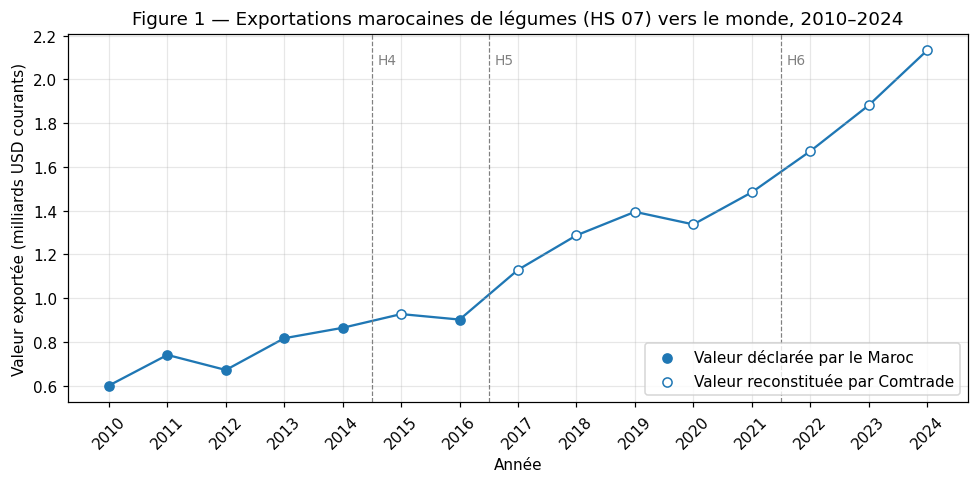

In [8]:
reconstituee = donnees.set_index('annee')['isAggregate'].astype(bool).values
changements_hs = donnees.loc[donnees['classificationCode'].ne(donnees['classificationCode'].shift()),
                             ['annee', 'classificationCode']].iloc[1:]

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(serie_mrd.index, serie_mrd.values, color='tab:blue', zorder=1)
ax.scatter(serie_mrd.index[~reconstituee], serie_mrd.values[~reconstituee],
           color='tab:blue', zorder=2, label='Valeur déclarée par le Maroc')
ax.scatter(serie_mrd.index[reconstituee], serie_mrd.values[reconstituee],
           facecolors='white', edgecolors='tab:blue', zorder=2, label='Valeur reconstituée par Comtrade')
for _, ligne in changements_hs.iterrows():
    ax.axvline(ligne['annee'] - 0.5, color='grey', linestyle='--', linewidth=0.8)
    ax.text(ligne['annee'] - 0.4, serie_mrd.max() * 0.97, ligne['classificationCode'], color='grey', fontsize=9)
ax.set(title='Figure 1 — Exportations marocaines de légumes (HS 07) vers le monde, 2010–2024',
       xlabel='Année', ylabel='Valeur exportée (milliards USD courants)')
ax.set_xticks(serie_mrd.index)
ax.tick_params(axis='x', rotation=45)
ax.legend(loc='lower right')
sauver(fig, 'figure1_evolution_exportations.png')

**Interprétation de la figure 1.** Les exportations marocaines de légumes passent d'environ 0,60 milliard de dollars en 2010 à 2,13 milliards en 2024, soit une multiplication par 3,5 en quinze ans. La hausse est presque continue : seules trois années reculent (2012, 2016 et 2020), et chaque baisse est rattrapée dès l'année suivante. La progression s'accélère à partir de 2017 et devient très régulière depuis 2021. Il faut toutefois rappeler que 2017 correspond aussi au passage à des valeurs reconstituées par Comtrade et à la nomenclature H5 (voir section 5) : une partie du saut de cette année pourrait venir de la méthode de construction des données, ce que nous ne pouvons pas vérifier avec la version preview.

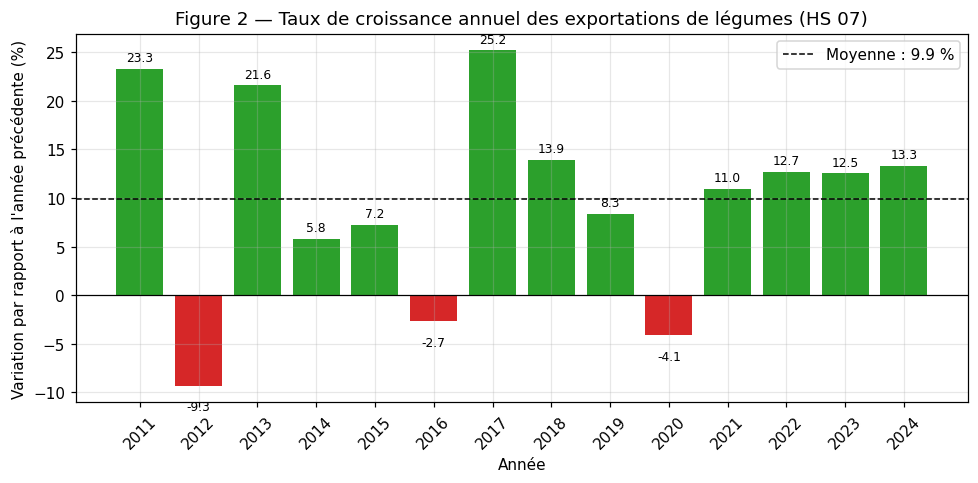

Écart-type des taux de croissance : 10.2 points


In [9]:
cr = croissance.dropna()
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.bar(cr.index, cr.values, color=['tab:red' if v < 0 else 'tab:green' for v in cr])
ax.axhline(0, color='black', linewidth=0.8)
ax.axhline(cr.mean(), color='black', linestyle='--', linewidth=1, label=f'Moyenne : {cr.mean():.1f} %')
for a, v in cr.items():
    ax.text(a, v + (0.8 if v >= 0 else -2.5), f'{v:.1f}', ha='center', fontsize=8)
ax.set(title='Figure 2 — Taux de croissance annuel des exportations de légumes (HS 07)',
       xlabel='Année', ylabel="Variation par rapport à l'année précédente (%)")
ax.set_xticks(cr.index)
ax.tick_params(axis='x', rotation=45)
ax.legend()
sauver(fig, 'figure2_croissance_annuelle.png')
print(f'Écart-type des taux de croissance : {cr.std():.1f} points')

**Interprétation de la figure 2.** La croissance annuelle moyenne est de 9,9 %, mais avec un écart-type de 10,2 points : la variabilité d'une année à l'autre est aussi grande que la croissance moyenne elle-même. Onze années sur quatorze sont en hausse. Les baisses restent limitées (au plus −9,3 % en 2012) et sont suivies de fortes reprises (+21,6 % en 2013, +25,2 % en 2017, +11,0 % en 2021). Depuis 2021, la croissance est remarquablement stable, entre 11 et 13 % par an. Pour la prévision, cela signifie qu'une erreur d'environ 10 % sur une année isolée sera difficile à éviter, quel que soit le modèle : les variations annuelles des exportations agricoles peuvent dépendre de facteurs (récoltes, prix, demande extérieure) que notre série seule ne contient pas.

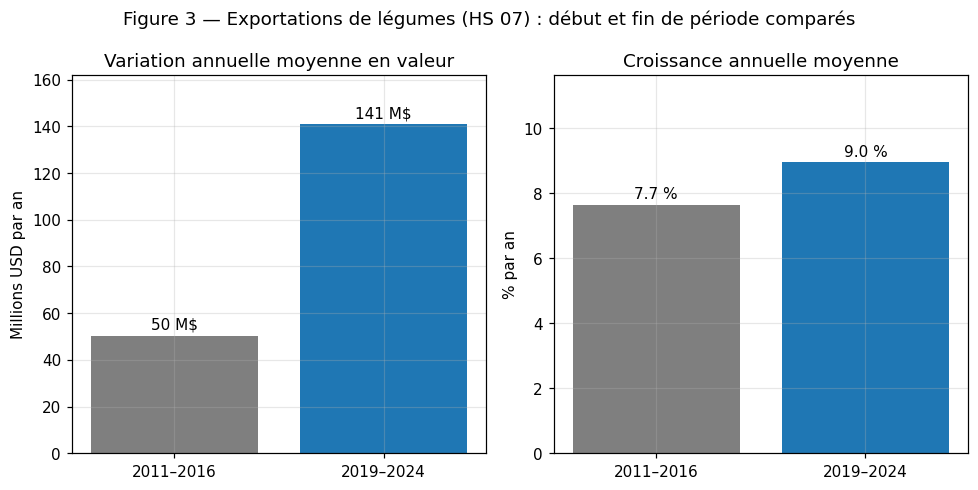

2011–2016 : variation moyenne 50 M$, croissance moyenne 7.7 %
2019–2024 : variation moyenne 141 M$, croissance moyenne 9.0 %


In [10]:
variation_m = (serie.diff() / 1e6).dropna()   # variation annuelle en millions USD
periodes = {'2011–2016': (2011, 2016), '2019–2024': (2019, 2024)}
moy_variation = [variation_m.loc[a:b].mean() for a, b in periodes.values()]
moy_croissance = [croissance.loc[a:b].mean() for a, b in periodes.values()]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(9, 4.5))
couleurs = ['tab:gray', 'tab:blue']

ax1.bar(periodes.keys(), moy_variation, color=couleurs)
ax1.set(title='Variation annuelle moyenne en valeur', ylabel='Millions USD par an')
ax1.set_ylim(0, max(moy_variation) * 1.15)
for i, v in enumerate(moy_variation):
    ax1.text(i, v + 3, f'{v:.0f} M$', ha='center', fontsize=10)

ax2.bar(periodes.keys(), moy_croissance, color=couleurs)
ax2.set(title='Croissance annuelle moyenne', ylabel='% par an', ylim=(0, max(moy_croissance) * 1.3))
for i, v in enumerate(moy_croissance):
    ax2.text(i, v + 0.2, f'{v:.1f} %', ha='center', fontsize=10)

fig.suptitle('Figure 3 — Exportations de légumes (HS 07) : début et fin de période comparés')
sauver(fig, 'figure3_comparaison_periodes.png')

# Valeurs utilisées dans l'interprétation
for (nom, (a, b)), v, c in zip(periodes.items(), moy_variation, moy_croissance):
    print(f'{nom} : variation moyenne {v:.0f} M$, croissance moyenne {c:.1f} %')

**Interprétation de la figure 3.** Nous comparons le début (2011–2016) et la fin (2019–2024) de la période. La croissance annuelle moyenne est proche sur les deux périodes : environ 7,7 % puis 9,0 %. En revanche, la variation annuelle moyenne en dollars est presque trois fois plus grande à la fin : environ 50 millions de dollars par an contre 141 millions. Par exemple, la hausse de 2011 (+23,3 %) ne représente que 140 millions de dollars, alors que celle de 2024, plus modeste en pourcentage (+13,3 %), en représente 251 millions. C'est donc surtout la taille du marché qui a changé, pas son rythme. Pour la modélisation, cela a deux conséquences : les erreurs de prévision en dollars seront mécaniquement plus grandes sur les années récentes, qui serviront de test (une erreur de 10 % en 2023 représente déjà près de 190 millions de dollars) ; et il est plus naturel de modéliser le taux de croissance que le niveau, puisque c'est lui qui reste stable.

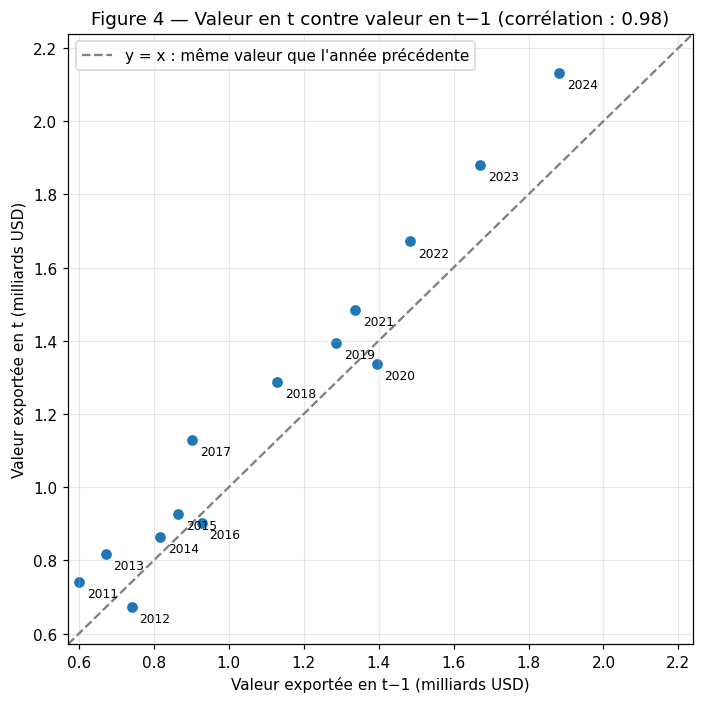

In [11]:
x = serie_mrd.shift(1).dropna()
y = serie_mrd.loc[x.index]
corr = np.corrcoef(x, y)[0, 1]
lim = [min(x.min(), y.min()) * 0.95, max(x.max(), y.max()) * 1.05]

fig, ax = plt.subplots(figsize=(6.5, 6.5))
ax.scatter(x, y, color='tab:blue')
for a in x.index:
    ax.annotate(str(a), (x[a], y[a]), textcoords='offset points', xytext=(5, -10), fontsize=8)
ax.plot(lim, lim, linestyle='--', color='grey', label="y = x : même valeur que l'année précédente")
ax.set(xlim=lim, ylim=lim,
       title=f'Figure 4 — Valeur en t contre valeur en t−1 (corrélation : {corr:.2f})',
       xlabel='Valeur exportée en t−1 (milliards USD)', ylabel='Valeur exportée en t (milliards USD)')
ax.legend(loc='upper left')
sauver(fig, 'figure4_persistance.png')

**Interprétation de la figure 4.** La corrélation entre la valeur d'une année et celle de l'année précédente est de 0,98 : la série est très persistante, ce qui va dans le sens de l'hypothèse H1. La plupart des points se situent au-dessus de la diagonale y = x, c'est-à-dire que la valeur augmente presque chaque année. Seules 2012, 2016 et 2020 sont en dessous. Conséquence pour la modélisation : une prévision par persistance (« même valeur que l'année précédente ») sera proche de la réalité, mais elle sous-estimera systématiquement les années de croissance. Une référence qui ajoute la croissance moyenne observée dans le passé pourrait faire mieux ; nous la testerons à la section 9.

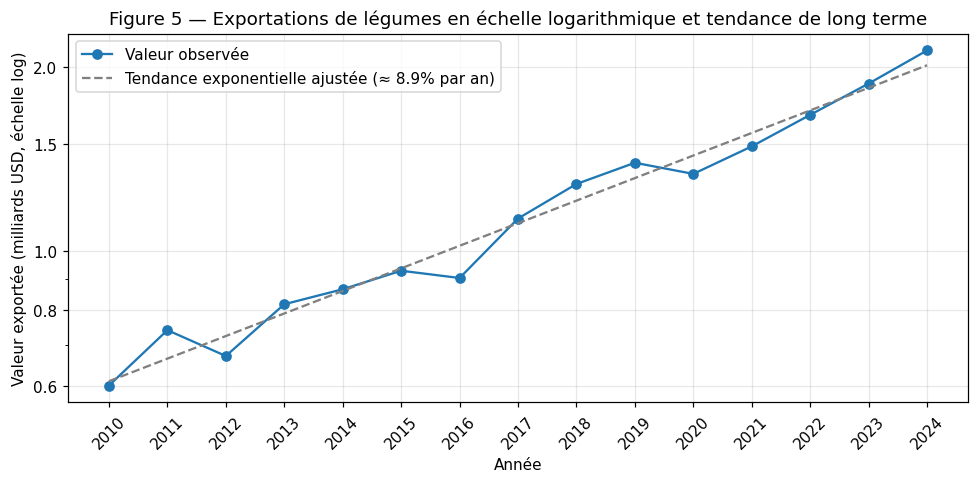

Taux de croissance annuel moyen 2010–2024 : 9.5%


In [12]:
from matplotlib.ticker import ScalarFormatter

annees_num = serie.index.values
coef = np.polyfit(annees_num, np.log(serie.values), 1)        # tendance log-linéaire
tendance_mrd = np.exp(np.polyval(coef, annees_num)) / 1e9
tcam = (serie.iloc[-1] / serie.iloc[0]) ** (1 / (len(serie) - 1)) - 1

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(annees_num, serie_mrd.values, marker='o', label='Valeur observée')
ax.plot(annees_num, tendance_mrd, linestyle='--', color='grey',
        label=f'Tendance exponentielle ajustée (≈ {np.exp(coef[0]) - 1:.1%} par an)')
ax.set_yscale('log')
ax.yaxis.set_major_formatter(ScalarFormatter())
ax.set(title='Figure 5 — Exportations de légumes en échelle logarithmique et tendance de long terme',
       xlabel='Année', ylabel='Valeur exportée (milliards USD, échelle log)')
ax.set_xticks(annees_num)
ax.tick_params(axis='x', rotation=45)
ax.legend(loc='upper left')
ax.set_yticks([0.6, 0.8, 1.0, 1.5, 2.0])
ax.yaxis.set_minor_formatter(plt.NullFormatter())
sauver(fig, 'figure5_echelle_log_tendance.png')
print(f'Taux de croissance annuel moyen 2010–2024 : {tcam:.1%}')

**Interprétation de la figure 5.** En échelle logarithmique, la série suit approximativement une droite, ce qui indique une croissance à taux à peu près constant. Le taux de croissance annuel moyen entre 2010 et 2024 est de 9,5 %, et la tendance exponentielle ajustée donne environ 8,9 % par an. Ces deux chiffres sont inférieurs à la moyenne simple des taux annuels (9,9 %, figure 2), car la moyenne arithmétique surestime la croissance réelle lorsque les variations sont irrégulières. Économiquement, le secteur suit une dynamique de croissance régulière plutôt qu'une simple hausse de niveau, ce qui justifie de tester un modèle qui prévoit le taux de croissance plutôt que la valeur. La tendance tracée ici est ajustée sur toute la période, y compris les années qui serviront de test : elle sert uniquement à décrire la série et ne sera jamais utilisée dans les modèles.

## 7. Construction des variables

**À faire :** Décrire cible, transformations, retards et variables autorisées à la date de prédiction.

**Réponse du binôme :** 

**Principe.** Nous nous plaçons à la fin de chaque année t et cherchons à prévoir l'année t+1. Seules les informations disponibles à la fin de l'année t peuvent servir de variables explicatives ; toute information de l'année t+1 ou postérieure est exclue pour éviter une fuite temporelle.

**Cibles.**
- Cible principale : `cible_valeur_t1`, la valeur exportée en t+1 (dollars courants).
- Cible alternative : `cible_croissance_t1`, le taux de croissance entre t et t+1. L'analyse exploratoire a montré que la croissance est plus stable que le niveau (figures 3 et 5) ; une croissance prévue se reconvertit en valeur par la formule valeur prévue = `valeur_t` × (1 + croissance prévue).

**Variables explicatives** (toutes connues à la fin de l'année t) :

| Variable | Définition |
|---|---|
| `valeur_t` | Valeur exportée en t |
| `valeur_t_1` | Valeur exportée en t−1 (retard d'un an) |
| `croissance_t` | Taux de croissance entre t−1 et t |
| `croissance_t_1` | Taux de croissance entre t−2 et t−1 |
| `croissance_moy_passee` | Moyenne des taux de croissance observés depuis 2011 jusqu'à t |
| `tendance` | Nombre d'années écoulées depuis 2010 |

Les croissances sont exprimées en proportion (0,10 = 10 %). Les variables ayant des échelles très différentes (milliards de dollars contre proportions), elles devront être standardisées dans les pipelines de modélisation.

**Variables exclues.** Les indicateurs de qualité (`classificationCode`, `isReported`, `isAggregate`, `legacyEstimationFlag`) ne sont pas utilisés comme variables explicatives. Ils décrivent la construction des données et non l'activité économique ; avec si peu d'observations, ils risqueraient surtout de faire surapprendre le modèle. Leur effet possible sera étudié dans l'analyse de sensibilité (section 13).

**Observations utilisables.** Le calcul des retards fait perdre les deux premières années (2010 et 2011), et la dernière année (2024) n'a pas encore de cible. Il reste donc **12 observations**, de t = 2012 à t = 2023 (cibles de 2013 à 2024). La ligne de 2024 est conservée à part : elle servira à produire la prévision pour 2025.

**Contrôle de la fuite temporelle.** Nous avons multiplié par 10 la valeur de 2024, puis reconstruit les variables. Les variables de 2010 à 2023 restent strictement identiques (test : `True`) : aucune ne dépend d'une information future. Le tableau complet est sauvegardé dans `data/variables_modele.csv`.

In [13]:
def construire_variables(donnees):
    """Pour chaque année t : variables connues à la fin de t, et cibles en t+1."""
    y = donnees.sort_values('annee').set_index('annee')['valeur_usd']
    tab = pd.DataFrame(index=y.index)

    # Variables explicatives (uniquement des informations disponibles à la fin de l'année t)
    tab['valeur_t'] = y
    tab['valeur_t_1'] = y.shift(1)
    tab['croissance_t'] = y.pct_change()
    tab['croissance_t_1'] = tab['croissance_t'].shift(1)
    tab['croissance_moy_passee'] = tab['croissance_t'].expanding().mean()
    tab['tendance'] = tab.index - tab.index.min()

    # Cibles (année t+1) : jamais utilisées comme variables explicatives
    tab['cible_valeur_t1'] = y.shift(-1)
    tab['cible_croissance_t1'] = tab['cible_valeur_t1'] / tab['valeur_t'] - 1
    return tab


VARIABLES = ['valeur_t', 'valeur_t_1', 'croissance_t', 'croissance_t_1',
             'croissance_moy_passee', 'tendance']
CIBLE = 'cible_valeur_t1'
CIBLE_CROISSANCE = 'cible_croissance_t1'

tableau = construire_variables(donnees)

# Lignes utilisables pour l'apprentissage : toutes les variables ET la cible sont connues
donnees_modele = tableau.dropna(subset=VARIABLES + [CIBLE])
# Ligne de prévision : dernière année observée (2024), cible 2025 inconnue
ligne_prevision = tableau.loc[[tableau.index.max()], VARIABLES]

print(f'Lignes utilisables : {len(donnees_modele)} '
      f'(t = {donnees_modele.index.min()} à {donnees_modele.index.max()}, '
      f'cibles {donnees_modele.index.min() + 1} à {donnees_modele.index.max() + 1})')
print('Ligne de prévision : t =', ligne_prevision.index[0], '(pour prévoir', ligne_prevision.index[0] + 1, ')')

# Affichage lisible : valeurs en milliards USD, croissances en %
apercu = donnees_modele.copy()
for c in ['valeur_t', 'valeur_t_1', 'cible_valeur_t1']:
    apercu[c] = (apercu[c] / 1e9).round(3)
for c in ['croissance_t', 'croissance_t_1', 'croissance_moy_passee', 'cible_croissance_t1']:
    apercu[c] = (apercu[c] * 100).round(1)
display(apercu)

# Test anti-fuite : on multiplie par 10 la valeur de 2024.
# Si les variables des années 2010 à 2023 ne changent pas, aucune ne dépend du futur.
donnees_test = donnees.copy()
donnees_test.loc[donnees_test['annee'] == 2024, 'valeur_usd'] *= 10
tableau_test = construire_variables(donnees_test)
inchangees = tableau.loc[:2023, VARIABLES].equals(tableau_test.loc[:2023, VARIABLES])
print('Test anti-fuite : variables 2010–2023 inchangées après modification de 2024 :', inchangees)

tableau.to_csv(DOSSIER_DATA / 'variables_modele.csv')

Lignes utilisables : 12 (t = 2012 à 2023, cibles 2013 à 2024)
Ligne de prévision : t = 2024 (pour prévoir 2025 )


,valeur_t,valeur_t_1,croissance_t,croissance_t_1,croissance_moy_passee,tendance,cible_valeur_t1,cible_croissance_t1
annee,,,,,,,,
2012,0.672,0.741,-9.3,23.3,7.0,2,0.817,21.6
2013,0.817,0.672,21.6,-9.3,11.9,3,0.865,5.8
2014,0.865,0.817,5.8,21.6,10.3,4,0.928,7.2
2015,0.928,0.865,7.2,5.8,9.7,5,0.903,-2.7
2016,0.903,0.928,-2.7,7.2,7.7,6,1.130,25.2
2017,1.130,0.903,25.2,-2.7,10.2,7,1.287,13.9
2018,1.287,1.130,13.9,25.2,10.6,8,1.395,8.3
2019,1.395,1.287,8.3,13.9,10.4,9,1.337,-4.1
2020,1.337,1.395,-4.1,8.3,8.9,10,1.484,11.0


Test anti-fuite : variables 2010–2023 inchangées après modification de 2024 : True


## 8. Découpage et validation

**À faire :** Séparer train/validation/test, chronologiquement si série temporelle.

**Réponse du binôme :**

Les données forment une série temporelle : un découpage aléatoire mélangerait passé et futur et ferait apprendre le modèle sur des années postérieures à celles qu'il doit prévoir. Nous utilisons donc un **découpage chronologique** des 12 observations :

| Jeu | Années t | Années prévues (t+1) | Observations |
|---|---|---|---|
| Entraînement | 2012–2018 | 2013–2019 | 7 |
| Validation | 2019–2020 | 2020–2021 | 2 |
| Test | 2021–2023 | 2022–2024 | 3 |

- **Entraînement** : ajustement des modèles.
- **Validation** : comparaison des modèles et choix des réglages.
- **Test** : évaluation finale, utilisée **une seule fois**, après tous les choix de modélisation. Les années de test ne servent jamais au réglage.

**Validation croisée temporelle.** Deux années de validation ne suffisent pas pour comparer des modèles de façon fiable. Pour le réglage des hyperparamètres, nous utilisons donc aussi une validation croisée à fenêtre croissante (`TimeSeriesSplit`, 5 plis, une année par pli) sur l'ensemble entraînement + validation : à chaque pli, le modèle est entraîné sur toutes les années disponibles jusqu'à t et prévoit l'année suivante. Les cinq plis prévoient successivement 2017, 2018, 2019, 2020 et 2021. Toute transformation des données (standardisation notamment) est intégrée dans un pipeline et ajustée uniquement sur la partie entraînement de chaque pli.

**Points d'attention.**
- La validation contient 2020, année de baisse (−4,1 %), puis le rebond de 2021 : elle mesure en partie la capacité des modèles à réagir à un choc.
- Toutes les valeurs à prévoir dans le test (de 1,67 à 2,13 milliards de dollars), ainsi que 2021 en validation (1,48 milliard), sont supérieures au maximum observé en entraînement (1,40 milliard). Les modèles devront donc extrapoler au-delà de ce qu'ils ont vu, ce qui pénalise particulièrement les modèles à base d'arbres, incapables de prévoir une valeur plus grande que celles de l'entraînement. C'est une raison supplémentaire de tester la cible exprimée en croissance.
- Avec si peu d'observations, les scores seront sensibles à chaque année ; ils devront être interprétés avec prudence.

,jeu,annees_t,annees_prevues,nb_lignes,cible_min_mrd_usd,cible_max_mrd_usd
0,entraînement,2012–2018,2013–2019,7,0.817,1.395
1,validation,2019–2020,2020–2021,2,1.337,1.484
2,test,2021–2023,2022–2024,3,1.672,2.132


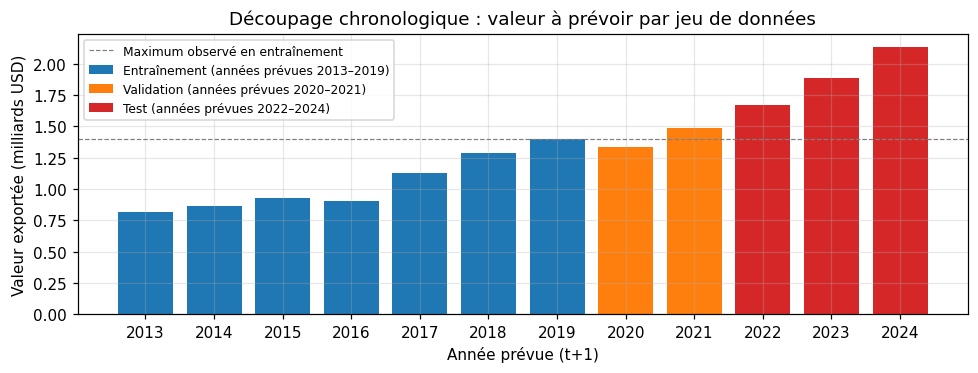

Validation croisée temporelle (fenêtre croissante, une année prévue par pli) :
  Pli 1 : entraînement t = 2012–2015 (4 lignes) → prévision de 2017
  Pli 2 : entraînement t = 2012–2016 (5 lignes) → prévision de 2018
  Pli 3 : entraînement t = 2012–2017 (6 lignes) → prévision de 2019
  Pli 4 : entraînement t = 2012–2018 (7 lignes) → prévision de 2020
  Pli 5 : entraînement t = 2012–2019 (8 lignes) → prévision de 2021


In [14]:
# Découpage chronologique (l'index est l'année t ; la cible correspond à t+1)
ANNEES_TRAIN = list(range(2012, 2019))   # t = 2012–2018 → cibles 2013–2019
ANNEES_VAL = [2019, 2020]                # t = 2019–2020 → cibles 2020–2021
ANNEES_TEST = [2021, 2022, 2023]         # t = 2021–2023 → cibles 2022–2024

X = donnees_modele[VARIABLES]
y = donnees_modele[CIBLE]
y_croissance = donnees_modele[CIBLE_CROISSANCE]

X_train, y_train = X.loc[ANNEES_TRAIN], y.loc[ANNEES_TRAIN]
X_val, y_val = X.loc[ANNEES_VAL], y.loc[ANNEES_VAL]
X_test, y_test = X.loc[ANNEES_TEST], y.loc[ANNEES_TEST]

# Vérifications : toutes les lignes utilisées une seule fois, ordre chronologique respecté
assert len(X_train) + len(X_val) + len(X_test) == len(donnees_modele)
assert max(ANNEES_TRAIN) < min(ANNEES_VAL) and max(ANNEES_VAL) < min(ANNEES_TEST)

resume_decoupage = pd.DataFrame({
    'jeu': ['entraînement', 'validation', 'test'],
    'annees_t': [f'{a[0]}–{a[-1]}' for a in (ANNEES_TRAIN, ANNEES_VAL, ANNEES_TEST)],
    'annees_prevues': [f'{a[0] + 1}–{a[-1] + 1}' for a in (ANNEES_TRAIN, ANNEES_VAL, ANNEES_TEST)],
    'nb_lignes': [len(y_train), len(y_val), len(y_test)],
    'cible_min_mrd_usd': [round(s.min() / 1e9, 3) for s in (y_train, y_val, y_test)],
    'cible_max_mrd_usd': [round(s.max() / 1e9, 3) for s in (y_train, y_val, y_test)],
})
display(resume_decoupage)

# Visualisation du découpage
fig, ax = plt.subplots(figsize=(9, 3.5))
for nom, annees, couleur in [('Entraînement', ANNEES_TRAIN, 'tab:blue'),
                             ('Validation', ANNEES_VAL, 'tab:orange'),
                             ('Test', ANNEES_TEST, 'tab:red')]:
    prevues = [a + 1 for a in annees]
    ax.bar(prevues, y.loc[annees].values / 1e9, color=couleur,
           label=f'{nom} (années prévues {prevues[0]}–{prevues[-1]})')
ax.axhline(y_train.max() / 1e9, color='grey', linestyle='--', linewidth=0.8,
           label='Maximum observé en entraînement')
ax.set(title='Découpage chronologique : valeur à prévoir par jeu de données',
       xlabel='Année prévue (t+1)', ylabel='Valeur exportée (milliards USD)')
ax.set_xticks(range(2013, 2025))
ax.legend(loc='upper left', fontsize=8)
sauver(fig, 'decoupage_chronologique.png')

# Validation croisée temporelle sur entraînement + validation (pour la section 11)
X_trainval = pd.concat([X_train, X_val])
y_trainval = pd.concat([y_train, y_val])
cv_temporelle = TimeSeriesSplit(n_splits=5, test_size=1)

print('Validation croisée temporelle (fenêtre croissante, une année prévue par pli) :')
for i, (idx_tr, idx_va) in enumerate(cv_temporelle.split(X_trainval), 1):
    a = X_trainval.index
    print(f'  Pli {i} : entraînement t = {a[idx_tr][0]}–{a[idx_tr][-1]} ({len(idx_tr)} lignes) '
          f'→ prévision de {a[idx_va][0] + 1}')

## 9. Modèle de référence

**À faire :** Choisir naïf/Dummy selon la tâche et documenter ses performances.

**Réponse du binôme :**

**Modèles de référence.** Nous utilisons deux règles simples, qui n'apprennent rien et n'utilisent que des informations connues à la fin de l'année t :

- **Persistance** (référence imposée par la fiche du projet) : la valeur prévue pour t+1 est égale à la valeur de l'année t.
- **Persistance + croissance moyenne** : la valeur prévue est la valeur de l'année t multipliée par (1 + croissance moyenne observée jusqu'en t). Cette référence est suggérée par la figure 4 : la série augmentant presque chaque année, la persistance seule devrait sous-estimer les années de croissance.

**Métriques.** Conformément à la fiche du projet, nous utilisons :
- la **MAE** (erreur absolue moyenne, en dollars) ;
- la **RMSE** (racine de l'erreur quadratique moyenne, en dollars), qui pénalise davantage les grosses erreurs ;
- le **WAPE** (somme des erreurs absolues divisée par la somme des valeurs réelles), qui exprime l'erreur en pourcentage du total exporté.

Les références sont évaluées sur la validation (années prévues 2020 et 2021) et sur les cinq plis de la validation croisée temporelle (années prévues 2017 à 2021). Le jeu de test n'est pas utilisé à ce stade.

**Résultats.**

| Référence | Jeu évalué | MAE (M$) | RMSE (M$) | WAPE (%) |
|---|---|---|---|---|
| Persistance | Validation (2020–2021) | 102,0 | 111,3 | 7,2 |
| Persistance | Validation croisée (2017–2021) | 139,3 | 150,2 | 10,5 |
| Persistance + croissance moyenne | Validation (2020–2021) | 114,7 | 144,3 | 8,1 |
| Persistance + croissance moyenne | Validation croisée (2017–2021) | 92,0 | 117,8 | 6,9 |

**Interprétation.** Le classement des deux références s'inverse selon le jeu d'évaluation. Sur la validation, la persistance est meilleure : en 2020, année de baisse (−4,1 %), elle reste proche de la réalité, alors que la référence avec croissance prévoit une hausse et se trompe d'environ 203 millions de dollars. En revanche, en 2021, année de reprise, c'est la référence avec croissance qui est la plus précise (27 millions d'erreur contre 147 millions pour la persistance). Sur les cinq années de la validation croisée, où la croissance est la situation la plus fréquente, la référence avec croissance est nettement meilleure (WAPE de 6,9 % contre 10,5 %).

Deux enseignements en découlent :
- Avec seulement deux années, la validation simple est trop sensible à une année atypique pour départager des modèles. La comparaison s'appuiera donc d'abord sur la validation croisée.
- Même les règles les plus simples se trompent en moyenne de 7 à 10 % de la valeur exportée, ce qui est cohérent avec l'hypothèse H1 : la série est très persistante, et les écarts viennent surtout des années de rupture, impossibles à anticiper à partir du passé seul.

Pour être jugé utile, un modèle alternatif devra faire mieux que **les deux** références, et en particulier que la persistance + croissance moyenne sur la validation croisée (WAPE de 6,9 %).

In [ ]:
def metriques(y_vrai, y_pred):
    """MAE, RMSE (en USD) et WAPE (proportion)."""
    y_vrai, y_pred = np.asarray(y_vrai, dtype=float), np.asarray(y_pred, dtype=float)
    erreur = y_vrai - y_pred
    return {'MAE': np.mean(np.abs(erreur)),
            'RMSE': np.sqrt(np.mean(erreur ** 2)),
            'WAPE': np.sum(np.abs(erreur)) / np.sum(np.abs(y_vrai))}


# Les deux modèles de référence (aucun apprentissage, uniquement des variables connues en t)
def persistance(X):
    return X['valeur_t'].values

def persistance_croissance(X):
    return (X['valeur_t'] * (1 + X['croissance_moy_passee'])).values

REFERENCES = {'Persistance': persistance,
              'Persistance + croissance moyenne': persistance_croissance}

# Tableau de résultats commun à tous les modèles
resultats = []

def enregistrer(modele, jeu, scores):
    for metrique, valeur in scores.items():
        resultats.append({'modele': modele, 'jeu_evalue': jeu, 'metrique': metrique, 'valeur': valeur})


# 1. Évaluation sur la validation (années prévues 2020 et 2021)
predictions_val = pd.DataFrame({'annee_prevue': y_val.index + 1,
                                'reel_mrd_usd': y_val.values / 1e9}, index=y_val.index)
for nom, regle in REFERENCES.items():
    pred = regle(X_val)
    predictions_val[nom] = pred / 1e9
    enregistrer(nom, 'validation (2020–2021)', metriques(y_val, pred))
print('Prévisions sur la validation (milliards USD) :')
display(predictions_val.round(3))

# 2. Évaluation sur les 5 plis de la validation croisée (années prévues 2017 à 2021)
for nom, regle in REFERENCES.items():
    vrais, preds = [], []
    for _, idx_va in cv_temporelle.split(X_trainval):
        vrais.extend(y_trainval.iloc[idx_va])
        preds.extend(regle(X_trainval.iloc[idx_va]))
    enregistrer(nom, 'validation croisée (2017–2021)', metriques(vrais, preds))

# Tableau récapitulatif lisible : MAE et RMSE en millions USD, WAPE en %
recap = (pd.DataFrame(resultats)
         .pivot_table(index=['modele', 'jeu_evalue'], columns='metrique', values='valeur'))
recap['MAE (M$)'] = (recap['MAE'] / 1e6).round(1)
recap['RMSE (M$)'] = (recap['RMSE'] / 1e6).round(1)
recap['WAPE (%)'] = (recap['WAPE'] * 100).round(1)
display(recap[['MAE (M$)', 'RMSE (M$)', 'WAPE (%)']])

Prévisions sur la validation (milliards USD) :


,annee_prevue,reel_mrd_usd,Persistance,Persistance + croissance moyenne
annee,,,,
2019,2020,1.337,1.395,1.540
2020,2021,1.484,1.337,1.457


metrique                                                         MAE (M$)  \
modele                           jeu_evalue                                 
Persistance                      validation (2020–2021)             102.0   
                                 validation croisée (2017–2021)     139.3   
Persistance + croissance moyenne validation (2020–2021)             114.7   
                                 validation croisée (2017–2021)      92.0   

metrique                                                         RMSE (M$)  \
modele                           jeu_evalue                                  
Persistance                      validation (2020–2021)              111.3   
                                 validation croisée (2017–2021)      150.2   
Persistance + croissance moyenne validation (2020–2021)              144.3   
                                 validation croisée (2017–2021)      117.8   

metrique                                                         WAPE (%)  
modele                           jeu_evalue                                
Persistance                      validation (2020–2021)               7.2  
                                 validation croisée (2017–2021)      10.5  
Persistance + croissance moyenne validation (2020–2021)               8.1  
                                 validation croisée (2017–2021)       6.9

## 10. Deux modèles alternatifs

**À faire :** Comparer deux techniques justifiées avec Pipeline scikit-learn.

**Réponse du binôme :**

**Modèles choisis.** Conformément à la fiche du projet, nous comparons deux techniques, chacune intégrée dans un `Pipeline` scikit-learn :

- **Ridge** (standardisation puis régression Ridge, `alpha = 1`) : une régression linéaire pénalisée. La pénalité stabilise les coefficients lorsque les variables sont fortement corrélées, ce qui est notre cas (`valeur_t`, `valeur_t_1` et `tendance` augmentent ensemble). Le modèle peut prolonger une tendance au-delà des valeurs observées et ses coefficients sont interprétables. La standardisation est indispensable, car les variables ont des échelles très différentes.
- **Gradient Boosting** (`GradientBoostingRegressor`, 100 arbres de profondeur 2, taux d'apprentissage 0,1, graine fixée) : une somme d'arbres de décision qui peut capter des relations non linéaires. Ses limites attendues sont le surapprentissage sur un petit échantillon et l'impossibilité de prévoir une valeur supérieure au maximum vu à l'entraînement.

Chaque modèle est testé avec deux versions de la cible : la **valeur** en t+1, et le **taux de croissance** entre t et t+1, reconverti ensuite en valeur (valeur prévue = `valeur_t` × (1 + croissance prévue)). Les quatre configurations sont évaluées comme les références, sur la validation et sur la validation croisée temporelle ; à chaque pli, une copie neuve du modèle est entraînée uniquement sur les années passées. Le jeu de test n'est pas utilisé.

**Résultats (validation croisée, années prévues 2017 à 2021).**

| Modèle | MAE (M$) | RMSE (M$) | WAPE (%) |
|---|---|---|---|
| Persistance + croissance moyenne (référence) | 92,0 | 117,8 | 6,9 |
| Gradient Boosting (croissance) | 129,0 | 139,2 | 9,7 |
| Persistance (référence) | 139,3 | 150,2 | 10,5 |
| Ridge (croissance) | 151,6 | 165,9 | 11,4 |
| Ridge (niveau) | 153,7 | 163,8 | 11,6 |
| Gradient Boosting (niveau) | 160,4 | 172,5 | 12,1 |

**Interprétation.**

- Avec les réglages par défaut, **aucun modèle ne fait mieux que la référence persistance + croissance moyenne**. Seul le Gradient Boosting appliqué à la croissance bat la persistance simple.
- Le classement sur la validation simple (2020–2021) est très différent : Ridge (niveau) y obtient le meilleur WAPE (6,1 %), alors qu'il est parmi les moins bons en validation croisée. Cela confirme qu'une évaluation sur deux années n'est pas fiable ; nos choix s'appuient sur la validation croisée.
- La limite du Gradient Boosting sur la valeur est clairement visible : ses prévisions pour 2020 et 2021 (1,38 et 1,33 milliard de dollars) restent sous le maximum observé à l'entraînement (1,40 milliard). Il ne peut donc pas suivre la croissance de la série et manque la reprise de 2021. En prévoyant la croissance plutôt que la valeur, cette limite disparaît (prévisions de 1,52 et 1,50 milliard) et le modèle devient le meilleur des quatre.
- La référence avec croissance moyenne est difficile à battre : les taux de croissance successifs varient beaucoup sans régularité apparente (par exemple +23 %, −9 %, +22 %, +6 % entre 2011 et 2014), si bien que les modèles apprennent surtout ces fluctuations, alors que la moyenne les lisse. Ce résultat va dans le sens de l'hypothèse H3 : avec 12 observations, un modèle plus complexe n'apporte pas d'avantage évident sur une règle simple.

Les hyperparamètres utilisés ici sont des valeurs par défaut ; leur réglage fait l'objet de la section 11.

In [16]:
from sklearn.linear_model import Ridge
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.base import clone


def creer_ridge(alpha=1.0):
    # Standardisation indispensable : les variables ont des échelles très différentes
    return Pipeline([('standardisation', StandardScaler()),
                     ('ridge', Ridge(alpha=alpha))])

def creer_gbr(**params):
    # Les arbres n'ont pas besoin de standardisation ; le pipeline garde une structure commune
    reglages = dict(n_estimators=100, max_depth=2, learning_rate=0.1,
                    random_state=GRAINE_ALEATOIRE)
    reglages.update(params)
    return Pipeline([('gbr', GradientBoostingRegressor(**reglages))])


def ajuster_predire(modele, X_app, X_pred, cible):
    """Entraîne une copie neuve du modèle sur X_app et renvoie des prévisions en valeur (USD)."""
    m = clone(modele)
    if cible == 'niveau':
        m.fit(X_app, y.loc[X_app.index])
        return m.predict(X_pred)
    # cible = 'croissance' : on prévoit le taux, puis on le reconvertit en valeur
    m.fit(X_app, y_croissance.loc[X_app.index])
    return X_pred['valeur_t'].values * (1 + m.predict(X_pred))


def evaluer(nom, modele, cible):
    """Évalue un modèle sur la validation et sur la validation croisée temporelle."""
    # Validation : entraînement sur 2012–2018, prévision de 2020 et 2021
    pred_val = ajuster_predire(modele, X_train, X_val, cible)
    enregistrer(nom, 'validation (2020–2021)', metriques(y_val, pred_val))
    # Validation croisée : un nouvel entraînement par pli, sur les seules années passées
    vrais, preds = [], []
    for idx_tr, idx_va in cv_temporelle.split(X_trainval):
        vrais.extend(y_trainval.iloc[idx_va])
        preds.extend(ajuster_predire(modele, X_trainval.iloc[idx_tr], X_trainval.iloc[idx_va], cible))
    enregistrer(nom, 'validation croisée (2017–2021)', metriques(vrais, preds))
    return pred_val


def tableau_recap(jeu):
    """Tableau lisible des résultats pour un jeu d'évaluation, trié par WAPE."""
    r = pd.DataFrame(resultats)
    r = r[r['jeu_evalue'] == jeu].pivot_table(index='modele', columns='metrique', values='valeur')
    return pd.DataFrame({'MAE (M$)': (r['MAE'] / 1e6).round(1),
                         'RMSE (M$)': (r['RMSE'] / 1e6).round(1),
                         'WAPE (%)': (r['WAPE'] * 100).round(1)}).sort_values('WAPE (%)')


MODELES = {
    'Ridge (niveau)': (creer_ridge(), 'niveau'),
    'Ridge (croissance)': (creer_ridge(), 'croissance'),
    'Gradient Boosting (niveau)': (creer_gbr(), 'niveau'),
    'Gradient Boosting (croissance)': (creer_gbr(), 'croissance'),
}

# Évite les doublons si la cellule est relancée : on ne garde que les références
resultats[:] = [r for r in resultats if r['modele'] in REFERENCES]

for nom, (modele, cible) in MODELES.items():
    predictions_val[nom] = evaluer(nom, modele, cible) / 1e9

print('Prévisions sur la validation (milliards USD) :')
display(predictions_val.round(3))
print('Validation croisée (2017–2021), triée par WAPE :')
display(tableau_recap('validation croisée (2017–2021)'))
print('Validation (2020–2021), triée par WAPE :')
display(tableau_recap('validation (2020–2021)'))

Prévisions sur la validation (milliards USD) :


,annee_prevue,reel_mrd_usd,Persistance,Persistance + croissance moyenne,Ridge (niveau),Ridge (croissance),Gradient Boosting (niveau),Gradient Boosting (croissance)
annee,,,,,,,,
2019,2020,1.337,1.395,1.540,1.478,1.518,1.381,1.521
2020,2021,1.484,1.337,1.457,1.516,1.537,1.333,1.501


Validation croisée (2017–2021), triée par WAPE :


,MAE (M$),RMSE (M$),WAPE (%)
modele,,,
Persistance + croissance moyenne,92.0,117.8,6.9
Gradient Boosting (croissance),129.0,139.2,9.7
Persistance,139.3,150.2,10.5
Ridge (croissance),151.6,165.9,11.4
Ridge (niveau),153.7,163.8,11.6
Gradient Boosting (niveau),160.4,172.5,12.1


Validation (2020–2021), triée par WAPE :


,MAE (M$),RMSE (M$),WAPE (%)
modele,,,
Ridge (niveau),86.5,102.0,6.1
Gradient Boosting (niveau),97.1,111.0,6.9
Gradient Boosting (croissance),100.1,130.3,7.1
Persistance,102.0,111.3,7.2
Persistance + croissance moyenne,114.7,144.3,8.1
Ridge (croissance),116.7,133.0,8.3


## 11. Hyperparamètres

**À faire :** Définir espace de recherche restreint et validation correcte.

**Réponse du binôme :**

**Espace de recherche.** Avec 12 observations, tester un grand nombre de combinaisons ferait courir le risque de retenir un réglage performant par hasard. Nous limitons donc la recherche à quelques valeurs :

| Modèle | Hyperparamètre | Valeurs testées |
|---|---|---|
| Ridge | `alpha` (force de la pénalité) | 0,01 ; 0,1 ; 1 ; 10 ; 100 |
| Gradient Boosting | `n_estimators` (nombre d'arbres) | 25 ; 50 ; 100 |
| | `max_depth` (profondeur des arbres) | 1 ; 2 |
| | `learning_rate` (taux d'apprentissage) | 0,05 ; 0,1 |

Chaque combinaison est testée avec les deux cibles (valeur et croissance), soit 34 essais (détail dans `data/recherche_hyperparametres.csv`).

**Validation.** Le réglage utilise uniquement la validation croisée temporelle (5 plis, années prévues 2017 à 2021) ; le jeu de test n'intervient pas. Le critère est le WAPE calculé sur la valeur exportée en dollars, y compris pour les modèles qui prévoient la croissance, afin que tous soient comparés sur la même grandeur. Nous avons écrit notre propre boucle plutôt que `GridSearchCV`, qui aurait mesuré l'erreur sur le taux de croissance et non sur la valeur.

**Meilleurs réglages (validation croisée 2017–2021).**

| Modèle | Réglage retenu | WAPE par défaut | WAPE réglé |
|---|---|---|---|
| Ridge (croissance) | alpha = 100 | 11,4 % | 7,5 % |
| Gradient Boosting (croissance) | 25 arbres, profondeur 1, taux 0,05 | 9,7 % | 7,8 % |
| Gradient Boosting (niveau) | 50 arbres, profondeur 1, taux 0,1 | 12,1 % | 11,4 % |
| Ridge (niveau) | alpha = 1 | 11,6 % | 11,6 % |
| *Référence persistance + croissance moyenne* | — | — | *6,9 %* |

**Interprétation.**

- Le réglage améliore nettement les modèles qui prévoient la croissance, mais **aucun ne fait mieux que la référence persistance + croissance moyenne**.
- Les meilleurs réglages sont systématiquement les plus contraints. Pour Ridge (croissance), l'erreur diminue à mesure que la pénalité augmente : avec une pénalité forte, les coefficients tendent vers zéro et le modèle prévoit pratiquement la croissance moyenne de l'entraînement, c'est-à-dire presque la même chose que la référence. Pour le Gradient Boosting (croissance), le meilleur réglage est le plus bridé de la grille (peu d'arbres, profondeur 1, taux faible). Autrement dit, les modèles sont d'autant meilleurs qu'ils s'appuient peu sur les variables explicatives : celles-ci n'apportent pas d'information utile au-delà de la croissance moyenne passée, ce qui confirme l'hypothèse H3.
- Pour Ridge (niveau), l'erreur suit une courbe en U selon `alpha` (voir la figure) : une pénalité trop faible conduit au surapprentissage (WAPE de 19,4 % avec alpha = 0,01), une pénalité trop forte ramène les prévisions vers le niveau moyen de l'entraînement et empêche de suivre la croissance (22,3 % avec alpha = 100). Le meilleur compromis est alpha = 1.
- Les versions qui prévoient directement la valeur restent les moins bonnes, même après réglage.

**Limite.** Les réglages sont choisis et comparés sur les mêmes cinq années ; le score du meilleur réglage est donc légèrement optimiste. Avec si peu d'observations, une validation croisée imbriquée n'est pas réalisable. Le jeu de test, qui n'a servi à aucun choix, fournira l'évaluation indépendante.

**Choix figés avant le test.** Sont évalués sur le test : les deux références et les quatre modèles réglés ci-dessus. Les modèles retenus pour la conclusion sont **Ridge (croissance, alpha = 100)** et **Gradient Boosting (croissance, 25 arbres, profondeur 1, taux 0,05)**, les meilleurs de chaque famille en validation croisée.

34 essais. Tous les résultats (validation croisée 2017–2021) :


,famille,cible,reglages,MAE (M$),WAPE (%)
22,Gradient Boosting,croissance,"arbres=25, profondeur=1, taux=0.05",102.9,7.75
31,Gradient Boosting,croissance,"arbres=100, profondeur=1, taux=0.1",103.7,7.81
24,Gradient Boosting,croissance,"arbres=25, profondeur=2, taux=0.05",107.5,8.10
30,Gradient Boosting,croissance,"arbres=100, profondeur=1, taux=0.05",108.8,8.20
27,Gradient Boosting,croissance,"arbres=50, profondeur=1, taux=0.1",110.0,8.29
26,Gradient Boosting,croissance,"arbres=50, profondeur=1, taux=0.05",114.4,8.62
23,Gradient Boosting,croissance,"arbres=25, profondeur=1, taux=0.1",115.5,8.70
28,Gradient Boosting,croissance,"arbres=50, profondeur=2, taux=0.05",120.1,9.05
25,Gradient Boosting,croissance,"arbres=25, profondeur=2, taux=0.1",125.2,9.44
32,Gradient Boosting,croissance,"arbres=100, profondeur=2, taux=0.05",125.9,9.49


Meilleur réglage par modèle et par cible :


,famille,cible,reglages,MAE (M$),WAPE (%)
22,Gradient Boosting,croissance,"arbres=25, profondeur=1, taux=0.05",102.9,7.75
10,Gradient Boosting,niveau,"arbres=50, profondeur=1, taux=0.1",150.8,11.36
21,Ridge,croissance,alpha=100,99.2,7.48
2,Ridge,niveau,alpha=1,153.7,11.58


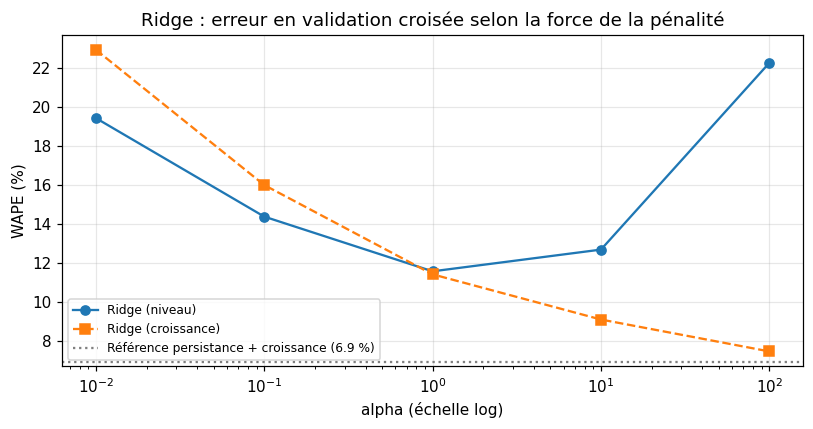

Comparaison complète en validation croisée (2017–2021) :


,MAE (M$),RMSE (M$),WAPE (%)
modele,,,
Persistance + croissance moyenne,92.0,117.8,6.9
Ridge (croissance) réglé,99.2,123.3,7.5
Gradient Boosting (croissance) réglé,102.9,127.0,7.8
Gradient Boosting (croissance),129.0,139.2,9.7
Persistance,139.3,150.2,10.5
Gradient Boosting (niveau) réglé,150.8,166.6,11.4
Ridge (croissance),151.6,165.9,11.4
Ridge (niveau),153.7,163.8,11.6
Ridge (niveau) réglé,153.7,163.8,11.6


In [17]:
from itertools import product

def score_cv(modele, cible):
    """Métriques (sur la valeur en USD) d'un modèle sur les 5 plis de la validation croisée."""
    vrais, preds = [], []
    for idx_tr, idx_va in cv_temporelle.split(X_trainval):
        vrais.extend(y_trainval.iloc[idx_va])
        preds.extend(ajuster_predire(modele, X_trainval.iloc[idx_tr], X_trainval.iloc[idx_va], cible))
    return metriques(vrais, preds)


# Espace de recherche restreint
ESPACE_RIDGE = {'alpha': [0.01, 0.1, 1, 10, 100]}
ESPACE_GBR = {'n_estimators': [25, 50, 100], 'max_depth': [1, 2], 'learning_rate': [0.05, 0.1]}

essais = []
for cible in ['niveau', 'croissance']:
    for alpha in ESPACE_RIDGE['alpha']:
        params = {'alpha': alpha}
        essais.append({'famille': 'Ridge', 'cible': cible, 'reglages': f'alpha={alpha}',
                       'params': params, **score_cv(creer_ridge(**params), cible)})
    for n, prof, lr in product(*ESPACE_GBR.values()):
        params = {'n_estimators': n, 'max_depth': prof, 'learning_rate': lr}
        essais.append({'famille': 'Gradient Boosting', 'cible': cible,
                       'reglages': f'arbres={n}, profondeur={prof}, taux={lr}',
                       'params': params, **score_cv(creer_gbr(**params), cible)})

essais = pd.DataFrame(essais)
essais['MAE (M$)'] = (essais['MAE'] / 1e6).round(1)
essais['WAPE (%)'] = (essais['WAPE'] * 100).round(2)
colonnes = ['famille', 'cible', 'reglages', 'MAE (M$)', 'WAPE (%)']

print(f'{len(essais)} essais. Tous les résultats (validation croisée 2017–2021) :')
display(essais.sort_values(['famille', 'cible', 'WAPE'])[colonnes])

# Meilleur réglage pour chaque modèle et chaque cible
meilleurs = essais.loc[essais.groupby(['famille', 'cible'])['WAPE'].idxmin()]
print('Meilleur réglage par modèle et par cible :')
display(meilleurs[colonnes])
essais.drop(columns='params').to_csv(DOSSIER_DATA / 'recherche_hyperparametres.csv', index=False)

# WAPE de la référence à battre, pour comparaison
r = pd.DataFrame(resultats)
wape_ref = r[(r['modele'] == 'Persistance + croissance moyenne')
             & (r['jeu_evalue'] == 'validation croisée (2017–2021)')
             & (r['metrique'] == 'WAPE')]['valeur'].iloc[0] * 100

# Courbe de validation de Ridge : erreur selon alpha
fig, ax = plt.subplots(figsize=(7.5, 4))
for cible, style in [('niveau', 'o-'), ('croissance', 's--')]:
    d = essais[(essais['famille'] == 'Ridge') & (essais['cible'] == cible)]
    ax.plot([p['alpha'] for p in d['params']], d['WAPE'] * 100, style, label=f'Ridge ({cible})')
ax.axhline(wape_ref, color='grey', linestyle=':', label=f'Référence persistance + croissance ({wape_ref:.1f} %)')
ax.set_xscale('log')
ax.set(title="Ridge : erreur en validation croisée selon la force de la pénalité",
       xlabel='alpha (échelle log)', ylabel='WAPE (%)')
ax.legend(fontsize=8)
sauver(fig, 'reglage_ridge_alpha.png')

# Enregistrement des 4 modèles réglés (validation + validation croisée)
resultats[:] = [x for x in resultats if not x['modele'].endswith('réglé')]
MODELES_REGLES = {}
for _, ligne in meilleurs.iterrows():
    nom = f"{ligne['famille']} ({ligne['cible']}) réglé"
    modele = creer_ridge(**ligne['params']) if ligne['famille'] == 'Ridge' else creer_gbr(**ligne['params'])
    MODELES_REGLES[nom] = (modele, ligne['cible'])
    predictions_val[nom] = evaluer(nom, modele, ligne['cible']) / 1e9

print('Comparaison complète en validation croisée (2017–2021) :')
display(tableau_recap('validation croisée (2017–2021)'))

## 12. Évaluation

**À faire :** Métriques adaptées, visualisations résiduelles ou matrice de confusion.

**Réponse du binôme :**

**Protocole.** Chaque modèle est réentraîné sur l'ensemble entraînement + validation (années t = 2012 à 2020), avec les réglages fixés à la section 11, puis évalué une seule fois sur le test (années prévues 2022, 2023 et 2024). Il s'agit de prévisions à un an : chaque année, la valeur de l'année écoulée est connue, mais les paramètres des modèles restent ceux appris sur 2012–2020. Aucun choix n'a été modifié après l'observation des résultats du test. Le tableau complet est sauvegardé dans `data/comparaison_modeles.csv`.

**Résultats.**

| Modèle | WAPE validation croisée (%) | MAE test (M$) | RMSE test (M$) | WAPE test (%) |
|---|---|---|---|---|
| Persistance + croissance moyenne (référence) | 6,9 | 58,1 | 58,6 | 3,1 |
| Ridge (croissance), alpha = 100 | 7,5 | 80,8 | 83,2 | 4,3 |
| Gradient Boosting (croissance), 25 arbres, profondeur 1 | 7,8 | 144,0 | 146,5 | 7,6 |
| Ridge (niveau), alpha = 1 | 11,6 | 189,1 | 203,6 | 10,0 |
| Persistance (référence) | 10,5 | 216,1 | 217,7 | 11,4 |
| Gradient Boosting (niveau), 50 arbres, profondeur 1 | 11,4 | 452,5 | 483,9 | 23,9 |

**Interprétation.**

- **Le classement de la validation croisée se confirme sur le test.** Les trois meilleurs modèles apparaissent dans le même ordre (référence persistance + croissance moyenne, puis Ridge et Gradient Boosting prévoyant la croissance), ce qui indique que notre procédure de sélection était fiable malgré le faible nombre d'observations.
- **Aucun modèle ne bat la référence persistance + croissance moyenne**, qui obtient un WAPE de 3,1 % sur le test, soit une erreur moyenne d'environ 58 millions de dollars par an. Le meilleur modèle d'apprentissage, Ridge appliqué à la croissance, s'en approche (4,3 %), sans la dépasser.
- **Les erreurs du test sont plus faibles qu'en validation croisée.** Cela ne traduit pas une amélioration des modèles : les années 2022 à 2024 connaissent une croissance très régulière (+12,7 %, +12,5 % et +13,3 %), sans choc comparable à ceux de 2016 ou de 2020, ce qui est la situation la plus favorable pour des règles fondées sur la croissance moyenne. Avec trois années de test, ces scores doivent être interprétés avec prudence.
- **Tous les modèles sous-estiment les trois années de test** (résidus tous positifs). Le secteur a accéléré à environ 12,5–13 % de croissance par an, alors que la croissance moyenne observée jusque-là était d'environ 9,5 %. Des modèles construits uniquement sur le passé de la série ne peuvent pas anticiper ce changement de rythme, d'où un biais systématique vers le bas.
- **La persistance sous-estime d'une année entière de croissance** (187, 209 et 251 millions de dollars), puisqu'elle suppose une valeur inchangée.
- **Le Gradient Boosting appliqué à la valeur illustre la limite des arbres de décision** : ses prévisions restent quasiment plates (1,41 puis 1,46 milliard de dollars), car il ne peut pas dépasser les valeurs vues à l'entraînement, alors que la valeur réelle atteint 2,13 milliards en 2024. Son erreur atteint 677 millions de dollars cette année-là. Prévoir la croissance plutôt que la valeur supprime ce problème (WAPE de 7,6 % au lieu de 23,9 %).

**Conclusion de l'évaluation.** Sur nos données, la meilleure prévision à un an consiste à prolonger la valeur actuelle au rythme de la croissance moyenne passée. Les modèles d'apprentissage n'apportent pas de gain mesurable, ce qui confirme l'hypothèse H3. Prévoir la croissance plutôt que la valeur est en revanche un choix décisif, pour Ridge comme pour le Gradient Boosting.

Prévisions sur le test (milliards USD) :


,annee_prevue,reel_mrd_usd,Persistance,Persistance + croissance moyenne,Gradient Boosting (croissance) réglé,Gradient Boosting (niveau) réglé,Ridge (croissance) réglé,Ridge (niveau) réglé
annee,,,,,,,,
2021,2022,1.672,1.484,1.619,1.561,1.414,1.611,1.567
2022,2023,1.881,1.672,1.829,1.737,1.457,1.807,1.706
2023,2024,2.132,1.881,2.063,1.955,1.457,2.025,1.845


Synthèse : validation croisée et test


,WAPE val. croisée (%),MAE test (M$),RMSE test (M$),WAPE test (%)
modele,,,,
Persistance + croissance moyenne,6.9,58.1,58.6,3.1
Ridge (croissance) réglé,7.5,80.8,83.2,4.3
Gradient Boosting (croissance) réglé,7.8,144.0,146.5,7.6
Ridge (niveau) réglé,11.6,189.1,203.6,10.0
Persistance,10.5,216.1,217.7,11.4
Gradient Boosting (niveau) réglé,11.4,452.5,483.9,23.9


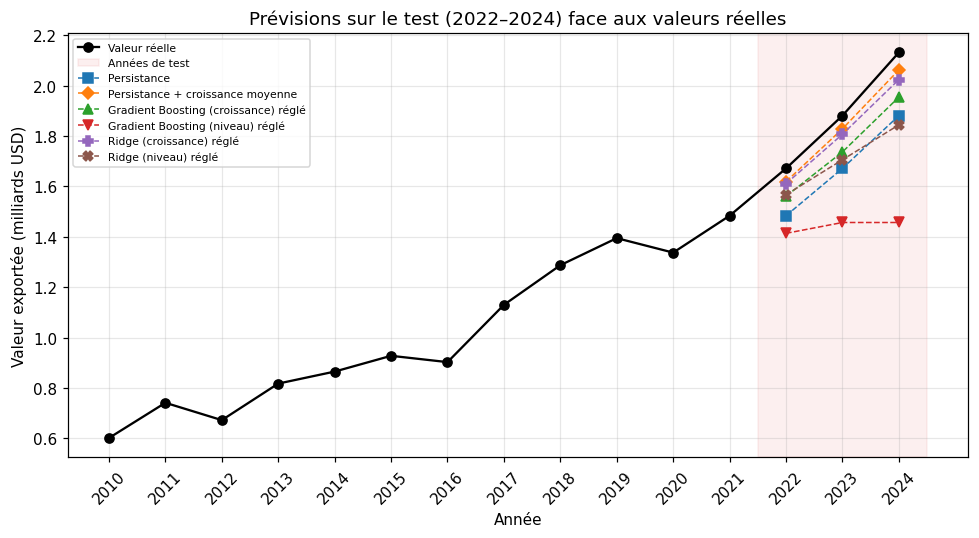

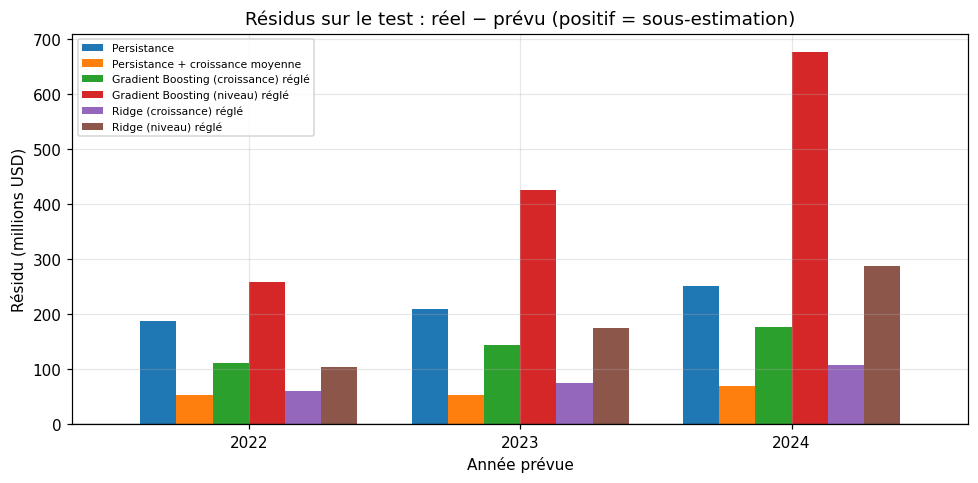

In [18]:
# ÉVALUATION FINALE SUR LE TEST : une seule fois, avec les choix figés en section 11
resultats[:] = [r for r in resultats if r['jeu_evalue'] != 'test (2022–2024)']

predictions_test = pd.DataFrame({'annee_prevue': y_test.index + 1,
                                 'reel_mrd_usd': y_test.values / 1e9}, index=y_test.index)

# Références : règles fixes, appliquées directement
for nom, regle in REFERENCES.items():
    pred = regle(X_test)
    predictions_test[nom] = pred / 1e9
    enregistrer(nom, 'test (2022–2024)', metriques(y_test, pred))

# Modèles réglés : entraînés sur entraînement + validation (t = 2012–2020)
for nom, (modele, cible) in MODELES_REGLES.items():
    pred = ajuster_predire(modele, X_trainval, X_test, cible)
    predictions_test[nom] = pred / 1e9
    enregistrer(nom, 'test (2022–2024)', metriques(y_test, pred))

print('Prévisions sur le test (milliards USD) :')
display(predictions_test.round(3))

# Tableau comparatif (format du template : modele, jeu_evalue, metrique, valeur)
comparaison = pd.DataFrame(resultats)
comparaison.to_csv(DOSSIER_DATA / 'comparaison_modeles.csv', index=False)

noms_finaux = list(REFERENCES) + list(MODELES_REGLES)
tab = (comparaison[comparaison['modele'].isin(noms_finaux)]
       .pivot_table(index='modele', columns=['jeu_evalue', 'metrique'], values='valeur'))
synthese = pd.DataFrame({
    'WAPE val. croisée (%)': (tab[('validation croisée (2017–2021)', 'WAPE')] * 100).round(1),
    'MAE test (M$)': (tab[('test (2022–2024)', 'MAE')] / 1e6).round(1),
    'RMSE test (M$)': (tab[('test (2022–2024)', 'RMSE')] / 1e6).round(1),
    'WAPE test (%)': (tab[('test (2022–2024)', 'WAPE')] * 100).round(1),
}).sort_values('WAPE test (%)')
print('Synthèse : validation croisée et test')
display(synthese)

# Figure A : prévisions face aux valeurs réelles
marqueurs = ['s', 'D', '^', 'v', 'P', 'X']
fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(serie_mrd.index, serie_mrd.values, 'k-o', label='Valeur réelle', zorder=3)
ax.axvspan(2021.5, 2024.5, color='tab:red', alpha=0.07, label='Années de test')
for nom, m in zip(noms_finaux, marqueurs):
    ax.plot(predictions_test['annee_prevue'], predictions_test[nom],
            linestyle='--', marker=m, linewidth=1, label=nom)
ax.set(title='Prévisions sur le test (2022–2024) face aux valeurs réelles',
       xlabel='Année', ylabel='Valeur exportée (milliards USD)')
ax.set_xticks(serie_mrd.index)
ax.tick_params(axis='x', rotation=45)
ax.legend(fontsize=7, loc='upper left')
sauver(fig, 'evaluation_previsions_test.png')

# Figure B : résidus (réel − prévu) par année de test, en millions USD
residus = pd.DataFrame({nom: (predictions_test['reel_mrd_usd'] - predictions_test[nom]) * 1000
                        for nom in noms_finaux})
residus.index = predictions_test['annee_prevue']
fig, ax = plt.subplots(figsize=(9, 4.5))
residus.plot(kind='bar', ax=ax, width=0.8)
ax.axhline(0, color='black', linewidth=0.8)
ax.set(title='Résidus sur le test : réel − prévu (positif = sous-estimation)',
       xlabel='Année prévue', ylabel='Résidu (millions USD)')
ax.tick_params(axis='x', rotation=0)
ax.legend(fontsize=7)
sauver(fig, 'evaluation_residus_test.png')

## 13. Sensibilité et interprétation

**À faire :** Variables importantes, incertitude et limites des hypothèses.

**Réponse du binôme :** 

Les analyses de cette section ne modifient aucun choix de modélisation : elles servent à comprendre les résultats et à tester leur solidité.

**1. Variables importantes** (modèles réglés, entraînés sur t = 2012–2020, voir la figure).

- **Ridge (croissance)** : la constante du modèle vaut 9,59 %, exactement la croissance moyenne des années d'entraînement. Les coefficients sont très faibles (au plus 0,5 point de croissance par écart-type de variable) : le modèle prévoit essentiellement la croissance moyenne, ce qui explique qu'il se rapproche de la référence persistance + croissance moyenne sans la dépasser. Les coefficients légèrement négatifs de `croissance_t` et `croissance_moy_passee` suggèrent un faible effet de rattrapage (une année de forte croissance serait suivie d'une croissance un peu plus faible), mais cet effet est trop faible et estimé sur trop peu d'observations pour être affirmé.
- **Gradient Boosting (croissance)** : 80 % de l'importance revient à `croissance_moy_passee`, et trois variables ne sont jamais utilisées. Le modèle a donc appris de lui-même à reproduire la logique de la référence.
- **Ridge (niveau)** : l'effet est réparti entre les variables de niveau (`tendance`, `valeur_t`, `valeur_t_1`), très corrélées entre elles, avec un coefficient négatif sur `croissance_moy_passee` qui compense. Dans cette situation, la répartition entre variables est en partie arbitraire, et les signes ne doivent pas être interprétés isolément.

En résumé, les deux meilleurs modèles convergent vers la même règle : prolonger la valeur actuelle au rythme de la croissance moyenne passée. Les autres variables n'apportent pas d'information utile.

**2. Incertitude.** Nous avons calculé l'erreur relative de la référence persistance + croissance moyenne pour chacune des 12 années prévues (2013 à 2024). L'erreur absolue moyenne est de 6,6 %. Les erreurs vont d'une surestimation de 13,1 % (2020) à une sous-estimation de 16,3 % (2017), et 80 % d'entre elles sont comprises entre −10,7 % et +12,6 % (quantiles 10 % et 90 %). Deux régimes apparaissent : jusqu'en 2020, des erreurs fortes dans les deux sens, concentrées sur les années de rupture (2013, 2016, 2017, 2020) ; depuis 2021, des erreurs faibles (+2 à +3 %) mais toujours positives, la référence restant légèrement en retard sur l'accélération récente. Cette fourchette d'environ −11 % / +13 % servira à encadrer la prévision 2025 (section 14). Elle reste approximative, car elle repose sur 12 observations et suppose que les chocs futurs ressembleront à ceux du passé.

**3. Tests de sensibilité.** Nous avons refait une prévision glissante année par année de 2017 à 2024 (chaque année, les modèles sont réentraînés sur toutes les années précédentes), puis comparé les modèles dans quatre scénarios :

| Modèle | Base 2017–2024 | Sans 2017 | Sans 2020 | Fenêtre glissante 5 ans |
|---|---|---|---|---|
| Persistance + croissance moyenne | 5,1 | 4,3 | 3,9 | 5,1 |
| Ridge (croissance) réglé | 5,6 | 4,7 | 4,4 | 5,6 |
| Gradient Boosting (croissance) réglé | 6,3 | 5,3 | 5,4 | 6,9 |
| Ridge (niveau) réglé | 9,6 | 8,5 | 9,5 | 10,2 |
| Persistance | 10,9 | 10,0 | 11,7 | 10,9 |
| Gradient Boosting (niveau) réglé | 12,6 | 11,7 | 13,9 | 13,9 |

*(WAPE en %)*

Le **classement des six modèles est identique dans les quatre scénarios**. Retirer 2017 (année qui cumule un changement de nomenclature et le passage à des données reconstituées) ou 2020 (choc de la pandémie) réduit les erreurs de tous les modèles, mais ne change aucune conclusion. Entraîner les modèles uniquement sur les cinq dernières années n'apporte aucun gain. Nos conclusions sont donc robustes aux choix de découpage et aux années atypiques. Le scénario de base inclut les années de test : il s'agit d'un contrôle de robustesse, dont aucune décision n'a été tirée.

**4. Limites des hypothèses.**

- **Bilan des hypothèses de départ.** H1 est confirmée : la série est très persistante. H2 est rejetée : les modèles d'apprentissage ne font pas mieux qu'une règle simple. H3 est confirmée : avec 12 observations, la complexité n'apporte rien.
- **Une seule série, sans variable externe.** Les modèles ne connaissent que le passé des exportations. Les facteurs qui expliquent réellement les ruptures (récoltes, prix internationaux, demande européenne, taux de change, conditions climatiques) sont absents ; c'est pourquoi aucune année de choc n'est anticipée.
- **Hypothèse de croissance stable.** La meilleure méthode suppose que la croissance future ressemblera à la moyenne passée. Elle sous-estime donc les périodes d'accélération, comme 2021–2024, et surestime les années de choc.
- **Valeurs nominales.** Les montants en dollars courants mélangent volumes, prix et taux de change ; une hausse de la valeur exportée ne signifie pas forcément une hausse des quantités.
- **Qualité des données.** La série combine des années déclarées et reconstituées, et quatre versions de la nomenclature HS ; les tests de sensibilité montrent toutefois que cela ne modifie pas nos conclusions.
- **Taille de l'échantillon.** Avec 12 observations et 3 années de test, tous les scores sont sensibles à chaque année ; les écarts de quelques dixièmes de point entre modèles ne sont pas significatifs.
- **Prévision et causalité.** Une bonne précision prédictive n'établit aucune relation de cause à effet : nos modèles décrivent une régularité statistique, ils n'expliquent pas pourquoi les exportations augmentent.

,Ridge croissance : coef. (points de croissance / écart-type),Ridge niveau : coef. (M$ / écart-type),Gradient Boosting croissance : importance (%)
valeur_t,-0.27,70.27,13.70
valeur_t_1,-0.17,56.16,0.00
croissance_t,-0.27,52.05,6.29
croissance_t_1,0.05,7.77,0.00
croissance_moy_passee,-0.51,-45.11,80.01
tendance,-0.15,102.73,0.00


Constante de Ridge (croissance) : 9.59 % | croissance moyenne des cibles d'entraînement : 9.59 %


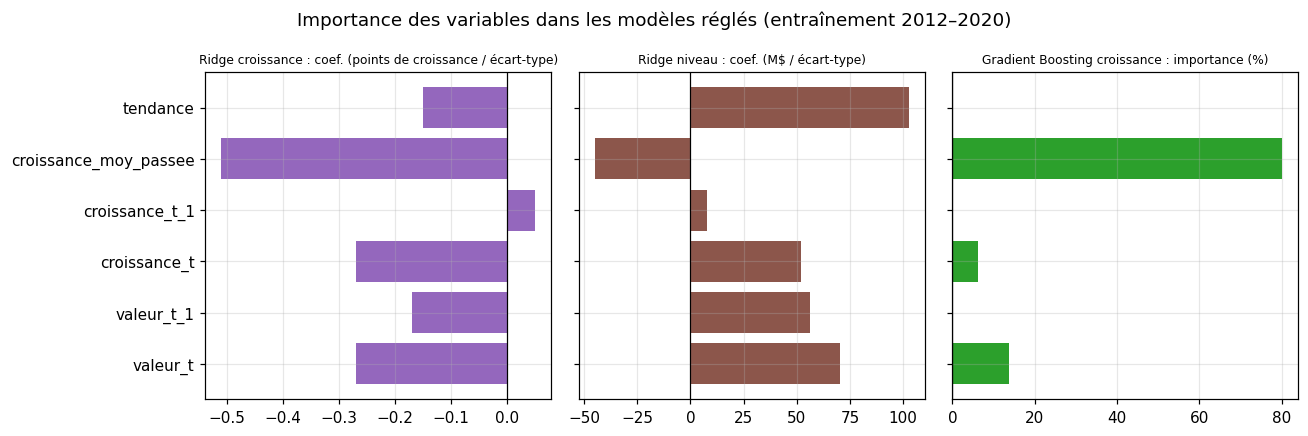

In [19]:
# A. Variables importantes (modèles réglés, entraînés sur t = 2012–2020)
y_croissance_trainval = y_croissance.loc[X_trainval.index]

ridge_cr = clone(MODELES_REGLES['Ridge (croissance) réglé'][0]).fit(X_trainval, y_croissance_trainval)
ridge_niv = clone(MODELES_REGLES['Ridge (niveau) réglé'][0]).fit(X_trainval, y_trainval)
gbr_cr = clone(MODELES_REGLES['Gradient Boosting (croissance) réglé'][0]).fit(X_trainval, y_croissance_trainval)

importances = pd.DataFrame({
    'Ridge croissance : coef. (points de croissance / écart-type)': ridge_cr.named_steps['ridge'].coef_ * 100,
    'Ridge niveau : coef. (M$ / écart-type)': ridge_niv.named_steps['ridge'].coef_ / 1e6,
    'Gradient Boosting croissance : importance (%)': gbr_cr.named_steps['gbr'].feature_importances_ * 100,
}, index=VARIABLES).round(2)
display(importances)

print(f"Constante de Ridge (croissance) : {ridge_cr.named_steps['ridge'].intercept_ * 100:.2f} % "
      f"| croissance moyenne des cibles d'entraînement : {y_croissance_trainval.mean() * 100:.2f} %")

fig, axes = plt.subplots(1, 3, figsize=(12, 4), sharey=True)
for ax, colonne, couleur in zip(axes, importances.columns, ['tab:purple', 'tab:brown', 'tab:green']):
    ax.barh(importances.index, importances[colonne], color=couleur)
    ax.axvline(0, color='black', linewidth=0.8)
    ax.set_title(colonne, fontsize=8)
fig.suptitle('Importance des variables dans les modèles réglés (entraînement 2012–2020)')
sauver(fig, 'importance_variables.png')

Erreurs relatives (réel / prévu − 1), en % :


annee,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024
erreur_relative,13.7,-5.4,-2.8,-11.3,16.3,3.4,-2.1,-13.1,1.9,3.2,2.9,3.4


Erreur absolue moyenne : 6.6 % | plus forte sous-estimation : 16.3 % | plus forte surestimation : -13.1 %
Quantiles 10 % et 90 % des erreurs : -10.7 % et 12.6 %


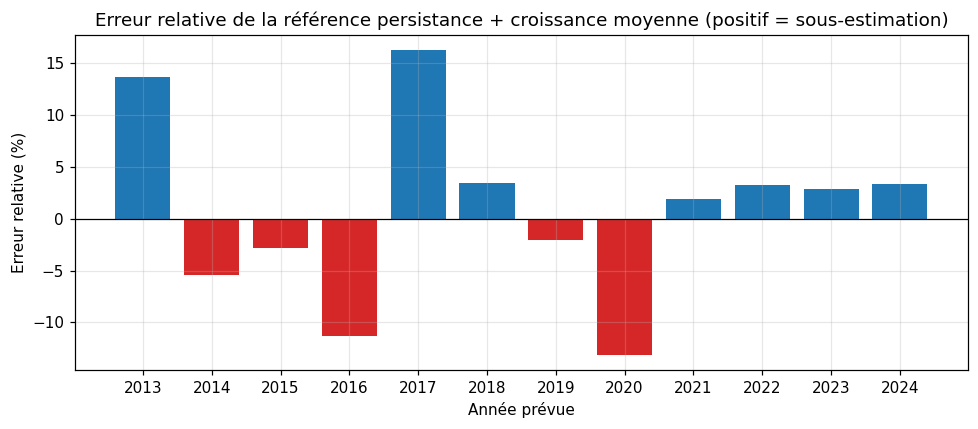

In [20]:
# B. Incertitude : erreurs relatives de la référence persistance + croissance moyenne, 2013–2024
pred_ref = persistance_croissance(X)                      # X = les 12 observations
erreurs_rel = pd.Series(y.values / pred_ref - 1, index=y.index + 1, name='erreur_relative')

print('Erreurs relatives (réel / prévu − 1), en % :')
display((erreurs_rel * 100).round(1).to_frame().T)
print(f'Erreur absolue moyenne : {erreurs_rel.abs().mean() * 100:.1f} % '
      f'| plus forte sous-estimation : {erreurs_rel.max() * 100:.1f} % '
      f'| plus forte surestimation : {erreurs_rel.min() * 100:.1f} %')

Q_BASSE, Q_HAUTE = erreurs_rel.quantile([0.1, 0.9])
print(f'Quantiles 10 % et 90 % des erreurs : {Q_BASSE * 100:.1f} % et {Q_HAUTE * 100:.1f} %')

fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(erreurs_rel.index, erreurs_rel * 100,
       color=['tab:red' if e < 0 else 'tab:blue' for e in erreurs_rel])
ax.axhline(0, color='black', linewidth=0.8)
ax.set(title='Erreur relative de la référence persistance + croissance moyenne (positif = sous-estimation)',
       xlabel='Année prévue', ylabel='Erreur relative (%)')
ax.set_xticks(erreurs_rel.index)
sauver(fig, 'incertitude_erreurs_reference.png')

In [21]:
# C. Sensibilité : prévision glissante année par année (t = 2016 à 2023, années prévues 2017 à 2024)
ANNEES_T_GLISSANT = list(range(2016, 2024))
reel_glissant = y.loc[ANNEES_T_GLISSANT]

def prevision_glissante(modele, cible, fenetre=None):
    """Pour chaque t : entraînement sur les années antérieures (ou les `fenetre` dernières), prévision de t+1."""
    previsions = {}
    for t in ANNEES_T_GLISSANT:
        if cible == 'regle':                         # référence : règle fixe, pas d'entraînement
            previsions[t] = modele(X.loc[[t]])[0]
            continue
        X_app = X.loc[X.index < t]
        if fenetre:
            X_app = X_app.loc[X_app.index >= t - fenetre]
        previsions[t] = ajuster_predire(modele, X_app, X.loc[[t]], cible)[0]
    return pd.Series(previsions)

CANDIDATS = {**{nom: (regle, 'regle') for nom, regle in REFERENCES.items()}, **MODELES_REGLES}
prev_croissante = {nom: prevision_glissante(m, c) for nom, (m, c) in CANDIDATS.items()}
prev_fenetre5 = {nom: prevision_glissante(m, c, fenetre=5) for nom, (m, c) in CANDIDATS.items()}

def wape_sur(prev, exclure=()):
    garder = [t for t in ANNEES_T_GLISSANT if t + 1 not in exclure]
    return metriques(reel_glissant.loc[garder], prev.loc[garder])['WAPE'] * 100

sensibilite = pd.DataFrame({
    'Base (2017–2024)': {n: wape_sur(p) for n, p in prev_croissante.items()},
    'Sans 2017': {n: wape_sur(p, exclure=(2017,)) for n, p in prev_croissante.items()},
    'Sans 2020': {n: wape_sur(p, exclure=(2020,)) for n, p in prev_croissante.items()},
    'Fenêtre glissante 5 ans': {n: wape_sur(p) for n, p in prev_fenetre5.items()},
}).round(1).sort_values('Base (2017–2024)')

print('WAPE (%) selon le scénario :')
display(sensibilite)
print('Rang de chaque modèle selon le scénario (1 = meilleur) :')
display(sensibilite.rank().astype(int))
sensibilite.to_csv(DOSSIER_DATA / 'sensibilite.csv')

WAPE (%) selon le scénario :


,Base (2017–2024),Sans 2017,Sans 2020,Fenêtre glissante 5 ans
Persistance + croissance moyenne,5.1,4.3,3.9,5.1
Ridge (croissance) réglé,5.6,4.7,4.4,5.6
Gradient Boosting (croissance) réglé,6.3,5.3,5.4,6.9
Ridge (niveau) réglé,9.6,8.5,9.5,10.2
Persistance,10.9,10.0,11.7,10.9
Gradient Boosting (niveau) réglé,12.6,11.7,13.9,13.9


Rang de chaque modèle selon le scénario (1 = meilleur) :


,Base (2017–2024),Sans 2017,Sans 2020,Fenêtre glissante 5 ans
Persistance + croissance moyenne,1,1,1,1
Ridge (croissance) réglé,2,2,2,2
Gradient Boosting (croissance) réglé,3,3,3,3
Ridge (niveau) réglé,4,4,4,4
Persistance,5,5,5,5
Gradient Boosting (niveau) réglé,6,6,6,6


## 14. Conclusion commerciale

**À faire :** Interprétation, limites et recommandations sous conditions.

**Réponse du binôme :**

**Réponse à la question de recherche.** Oui, il est possible de prévoir la valeur annuelle des exportations marocaines de légumes (HS 07) avec une erreur moyenne d'environ 3 à 7 % selon les périodes. Mais la meilleure méthode n'est pas un modèle d'apprentissage : c'est une règle simple, qui prolonge la valeur de l'année au rythme de la croissance moyenne passée. Ridge et le Gradient Boosting ne font pas mieux, et le Gradient Boosting appliqué directement à la valeur est même inutilisable, car il ne peut pas prévoir au-delà des valeurs déjà observées. Ces conclusions sont stables dans tous les tests de sensibilité (section 13).

**Prévision pour 2025.** En appliquant la méthode retenue à la valeur de 2024 (2,13 milliards de dollars) et à la croissance moyenne observée depuis 2011 (9,9 % par an), nous prévoyons **environ 2,34 milliards de dollars en 2025**, soit une hausse d'environ 10 %. Ridge (croissance) donne la même valeur (2,34 milliards) et le Gradient Boosting (croissance) une valeur un peu plus basse (2,28 milliards). D'après les erreurs passées de la méthode, la valeur réelle devrait se situer, dans environ 8 cas sur 10, **entre 2,09 et 2,64 milliards de dollars** : de la stagnation à une hausse de 24 %. Cette fourchette est indicative, car elle repose sur 12 observations.

**Recommandations sous conditions** (pour un exportateur ou un organisme d'appui aux exportations) :

- **Pour la planification de base**, retenir une hausse d'environ 10 % (environ 2,34 milliards de dollars au niveau national) comme hypothèse centrale pour dimensionner la production, la logistique et la prospection.
- **Pour les engagements financiers fermes** (investissements, contrats à coûts fixes), raisonner plutôt sur la borne basse (environ 2,09 milliards, soit une valeur stable par rapport à 2024), afin de conserver une marge en cas de mauvaise année.
- **Si la dynamique récente se poursuit**, la valeur pourrait atteindre environ 2,40 milliards (+12,4 %, rythme moyen de 2021–2024). Depuis 2021, notre méthode a sous-estimé chaque année de 2 à 3 % : il est prudent de prévoir des capacités logistiques (transport, stockage, chaîne du froid) capables d'absorber une hausse supérieure à la prévision centrale.
- **Si des signaux de choc apparaissent en cours d'année** (mauvaise récolte, conditions climatiques défavorables, chute de la demande sur les principaux marchés, tensions logistiques), il faut abandonner l'hypothèse centrale et envisager un scénario de baisse : un recul comparable à 2012 ramènerait la valeur à environ 1,93 milliard (−9 %). Notre modèle ne peut pas anticiper ces chocs ; il doit être complété par un suivi de ces indicateurs.
- **Avant de traduire la prévision en volumes**, tenir compte des prix et du taux de change : nos montants sont en dollars courants, et une hausse de la valeur peut venir des prix plutôt que des quantités exportées.

**Limites.** La prévision repose uniquement sur l'historique de la série : elle suppose que la croissance future ressemblera à la moyenne passée et ne voit aucun facteur externe. Elle porte sur le total national du chapitre HS 07, et non sur un produit ou un marché précis, ce qui limite son usage direct pour une entreprise donnée. Enfin, elle est établie à partir de 15 années, avec des données en partie reconstituées par Comtrade (section 5).

**Perspectives.**
- Ajouter des variables externes (prix internationaux, demande des principaux pays importateurs, taux de change, données climatiques), qui pourraient aider à anticiper les années de rupture.
- Travailler sur des données mensuelles pour disposer de plus d'observations et suivre la saison en cours.
- Descendre au niveau des produits (HS 4 ou HS 6, par exemple les tomates) et des marchés partenaires (France, Espagne), plus utiles pour une décision d'entreprise.
- Raisonner en volumes ou en valeurs déflatées, pour séparer l'effet des prix de celui des quantités.
- Comparer la prévision 2025 à la valeur réelle dès sa publication par UN Comtrade, pour une évaluation hors échantillon supplémentaire.

Valeur 2024 : 2.132 Md$ | croissance moyenne passée utilisée : 9.9 %


,valeur_2025_mrd_usd,variation_vs_2024_%
Persistance + croissance moyenne (méthode retenue),2.344,9.912
Ridge (croissance) réglé,2.343,9.882
Gradient Boosting (croissance) réglé,2.282,7.020
Borne basse de la fourchette (80 %),2.092,-1.884
Borne haute de la fourchette (80 %),2.640,23.798
Scénario : rythme récent (croissance moyenne 2021–2024),2.396,12.372
Scénario : choc comparable à 2012 (plus forte baisse observée),1.934,-9.296


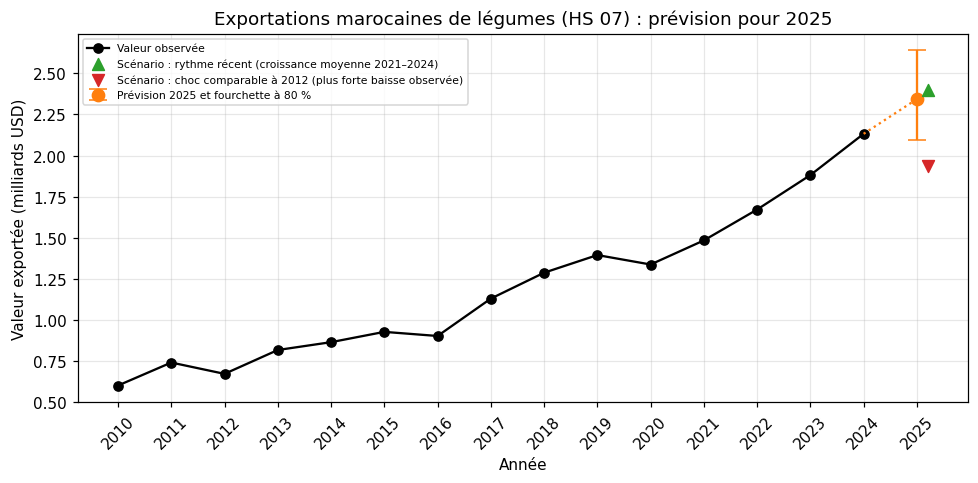

In [22]:
# Prévision 2025 : modèles réentraînés sur toutes les observations (t = 2012–2023)
valeur_2024 = ligne_prevision['valeur_t'].iloc[0]
cr_moy_2024 = ligne_prevision['croissance_moy_passee'].iloc[0]

prev_2025 = {'Persistance + croissance moyenne (méthode retenue)': persistance_croissance(ligne_prevision)[0]}
for nom in ['Ridge (croissance) réglé', 'Gradient Boosting (croissance) réglé']:
    modele, cible = MODELES_REGLES[nom]
    prev_2025[nom] = ajuster_predire(modele, X, ligne_prevision, cible)[0]

# Fourchette à 80 % : quantiles des erreurs passées de la méthode retenue (section 13)
centrale = prev_2025['Persistance + croissance moyenne (méthode retenue)']
borne_basse, borne_haute = centrale * (1 + Q_BASSE), centrale * (1 + Q_HAUTE)

# Scénarios illustratifs tirés des données observées
cr_recente = croissance.loc[2021:2024].mean() / 100
scenarios = {
    'Scénario : rythme récent (croissance moyenne 2021–2024)': valeur_2024 * (1 + cr_recente),
    'Scénario : choc comparable à 2012 (plus forte baisse observée)': valeur_2024 * (1 + croissance.min() / 100),
}

tableau_2025 = pd.Series({**prev_2025,
                          'Borne basse de la fourchette (80 %)': borne_basse,
                          'Borne haute de la fourchette (80 %)': borne_haute,
                          **scenarios}).to_frame('valeur_2025_mrd_usd')
tableau_2025['variation_vs_2024_%'] = (tableau_2025['valeur_2025_mrd_usd'] / valeur_2024 - 1) * 100
tableau_2025['valeur_2025_mrd_usd'] /= 1e9
print(f'Valeur 2024 : {valeur_2024 / 1e9:.3f} Md$ | croissance moyenne passée utilisée : {cr_moy_2024 * 100:.1f} %')
display(tableau_2025.round(3))
tableau_2025.to_csv(DOSSIER_DATA / 'prevision_2025.csv')

# Figure : série observée, prévision 2025, fourchette et scénarios
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(serie_mrd.index, serie_mrd.values, 'k-o', label='Valeur observée')
ax.plot([2024, 2025], [valeur_2024 / 1e9, centrale / 1e9], ':', color='tab:orange')
ax.errorbar(2025, centrale / 1e9,
            yerr=[[(centrale - borne_basse) / 1e9], [(borne_haute - centrale) / 1e9]],
            fmt='o', color='tab:orange', capsize=6, markersize=8,
            label='Prévision 2025 et fourchette à 80 %')
for (nom, v), m, c in zip(scenarios.items(), ['^', 'v'], ['tab:green', 'tab:red']):
    ax.scatter(2025.2, v / 1e9, marker=m, color=c, s=60, zorder=3, label=nom)
ax.set(title='Exportations marocaines de légumes (HS 07) : prévision pour 2025',
       xlabel='Année', ylabel='Valeur exportée (milliards USD)')
ax.set_xticks(range(2010, 2026))
ax.tick_params(axis='x', rotation=45)
ax.legend(fontsize=7, loc='upper left')
sauver(fig, 'prevision_2025.png')

## 15. Reproductibilité

**À faire :** Versions, seed, provenance, exécution intégrale et références.

**Réponse du binôme :** 

**Environnement.** Les versions de Python et des bibliothèques utilisées sont affichées par la cellule ci-dessous, et enregistrées dans `requirements.txt` (généré automatiquement par le notebook, avec les versions exactes). Pour recréer l'environnement : `pip install -r requirements.txt`.

**Graine aléatoire.** La seule source d'aléatoire est le Gradient Boosting, dont la graine est fixée (`random_state = GRAINE_ALEATOIRE = 42`). Le découpage des données est chronologique et la validation croisée (`TimeSeriesSplit`) ne mélange pas les observations : tous les résultats sont donc identiques d'une exécution à l'autre. La fonction `train_test_split`, importée par le template, n'est volontairement pas utilisée, car un découpage aléatoire serait inadapté à une série temporelle.

**Provenance des données.** Les données proviennent de l'API publique preview de UN Comtrade (Maroc, exportations vers le monde, chapitre HS 07, 2010–2024). Le jeu utilisé a été extrait le 14/11/2026. Les données brutes et le journal des requêtes (date, paramètres, statut) sont conservés dans `data/`. Par défaut (`FORCER_TELECHARGEMENT = False`), le notebook relit ces fichiers au lieu d'interroger de nouveau l'API : une nouvelle exécution donne exactement les mêmes chiffres, même si UN Comtrade révise ses données. Pour reproduire l'extraction elle-même, il suffit de passer `FORCER_TELECHARGEMENT = True`.

**Exécution intégrale.** Une exécution finale complète du notebook (« Restart » puis « Run All ») a été réalisée le 14/11/2026, sans erreur, de la première à la dernière cellule. Les chemins sont relatifs (`data/` et `figures/`), si bien qu'aucune modification n'est nécessaire d'un ordinateur à l'autre. Toutes les figures sont enregistrées en PNG (300 dpi) dans `figures/`, et les tableaux intermédiaires en CSV dans `data/`.

**Références.**
- Nations Unies, *UN Comtrade API — Documentation* : https://uncomtrade.org/docs/un-comtrade-api/
- Nations Unies, *UN Comtrade — Usage Agreement* : https://comtrade.un.org/licenseagreement.html
- Pedregosa et al. (2011), *Scikit-learn: Machine Learning in Python*, Journal of Machine Learning Research, 12, 2825–2830.
- Documentation de pandas, NumPy et Matplotlib.

**Usage d'outils d'IA.** Conformément aux règles de l'établissement, l'usage d'un assistant d'IA est déclaré dans le README et dans le rapport.


In [23]:
import sys
import platform
import sklearn
import matplotlib

# 1. Environnement d'exécution
print("Date d'exécution finale :", datetime.now().strftime('%Y-%m-%d %H:%M'))
print('Python :', sys.version.split()[0], '| Système :', platform.system(), platform.release())

VERSIONS = {'numpy': np.__version__, 'pandas': pd.__version__,
            'matplotlib': matplotlib.__version__, 'scikit-learn': sklearn.__version__,
            'requests': requests.__version__}
display(pd.Series(VERSIONS, name='version').to_frame())

# 2. Graine aléatoire
print('Graine aléatoire (GRAINE_ALEATOIRE) :', GRAINE_ALEATOIRE)

# 3. Provenance des données
journal_extraction = pd.read_csv(FICHIER_JOURNAL)
print(f"Extraction UN Comtrade : {journal_extraction['date_extraction'].min()} → "
      f"{journal_extraction['date_extraction'].max()} | {len(journal_extraction)} requêtes | "
      f"statuts : {sorted(int(s) for s in journal_extraction['statut'].unique())}")
print('Téléchargement forcé (FORCER_TELECHARGEMENT) :', FORCER_TELECHARGEMENT)

# 4. Fichiers produits par le notebook
fichiers = sorted(list(DOSSIER_DATA.glob('*')) + list(DOSSIER_FIG.glob('*')))
display(pd.DataFrame({'fichier': [str(f) for f in fichiers],
                      'taille_ko': [round(f.stat().st_size / 1024, 1) for f in fichiers]}))

# 5. requirements.txt avec les versions exactes utilisées
with open('requirements.txt', 'w') as f:
    for paquet, version in VERSIONS.items():
        f.write(f'{paquet}=={version}\n')
print('requirements.txt :')
print(open('requirements.txt').read())

Date d'exécution finale : 2026-11-14 01:10
Python : 3.13.3 | Système : Windows 11


,version
numpy,2.2.4
pandas,2.2.3
matplotlib,3.10.3
scikit-learn,1.7.2
requests,2.32.3


Graine aléatoire (GRAINE_ALEATOIRE) : 42
Extraction UN Comtrade : 2026-11-14 00:09 → 2026-11-14 00:10 | 15 requêtes | statuts : [200]
Téléchargement forcé (FORCER_TELECHARGEMENT) : False


,fichier,taille_ko
0,data\comparaison_modeles.csv,6.0
1,data\comtrade_maroc_HS07_X_2010_2024_brut.csv,2.8
2,data\donnees_propres.csv,0.6
3,data\journal_nettoyage.csv,0.4
4,data\journal_requetes.csv,2.8
5,data\prevision_2025.csv,0.6
6,data\recherche_hyperparametres.csv,4.1
7,data\sensibilite.csv,0.3
8,data\variables_modele.csv,1.9
9,figures\decoupage_chronologique.png,134.8


requirements.txt :
numpy==2.2.4
pandas==2.2.3
matplotlib==3.10.3
scikit-learn==1.7.2
requests==2.32.3

